# Tema 2 — IA: Clasificarea Imaginilor cu Rețele Neurale
**Seturi de date:** "Vai de pielea mea" (leziuni cutanate) & "You're on candid camera" (expresii faciale)

## 0. Imports și configurare globală

In [ ]:

COLAB_BASE = '/Users/anaciurea/Desktop/Tema2-IA-Colab'

assert os.path.isdir(os.path.join(COLAB_BASE, 'vai-de-pielea-mea')), \
    f'Nu găsesc vai-de-pielea-mea în {COLAB_BASE}'
assert os.path.isdir(os.path.join(COLAB_BASE, 'you-re-on-candid-camera')), \
    f'Nu găsesc you-re-on-candid-camera în {COLAB_BASE}'

print('Folderele de date au fost găsite.')
print(f'Base path: {COLAB_BASE}')


Folderele de date au fost găsite.
Base path: /Users/anaciurea/Desktop/Tema2-IA-Colab


In [ ]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image
from datetime import datetime
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler, Subset
from torch.utils.tensorboard import SummaryWriter
from torch.optim.lr_scheduler import LambdaLR, CosineAnnealingLR, SequentialLR

import torchvision
import torchvision.models as models
import torchvision.transforms as transforms

device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')
torch.manual_seed(42)
np.random.seed(42)

BASE     = COLAB_BASE
MOLE_DIR = os.path.join(BASE, 'vai-de-pielea-mea')
FACE_DIR = os.path.join(BASE, 'you-re-on-candid-camera')
RUNS_DIR = os.path.join(BASE, 'runs')
os.makedirs(RUNS_DIR, exist_ok=True)

Device: mps


---
## 1. Dataset-uri și DataLoader-e

In [3]:
# ---------- Dataset pentru "Vai de pielea mea" ----------
MOLE_CLASSES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
MOLE_CLASS2IDX = {c: i for i, c in enumerate(MOLE_CLASSES)}
MOLE_IDX2CLASS = {i: c for c, i in MOLE_CLASS2IDX.items()}
MOLE_MEAN = [0.7646, 0.5464, 0.5712]
MOLE_STD  = [0.1410, 0.1532, 0.1706]

# ---------- Dataset pentru "You're on candid camera" ----------
FACE_CLASSES = {1:'Surprise', 2:'Fear', 3:'Disgust', 4:'Happiness', 5:'Sadness', 6:'Anger', 7:'Neutral'}
FACE_CLASS2IDX = {v: k-1 for k, v in FACE_CLASSES.items()}  # 0-indexed
FACE_IDX2CLASS = {k-1: v for k, v in FACE_CLASSES.items()}

with open(os.path.join(FACE_DIR, 'splits', 'norm_stats.json')) as f:
    _ns = json.load(f)
FACE_MEAN = _ns['mean']
FACE_STD  = _ns['std']

print('Mole classes:', MOLE_CLASSES)
print('Face classes:', list(FACE_CLASSES.values()))
print(f'Face norm  mean={FACE_MEAN}, std={FACE_STD}')

Mole classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Face classes: ['Surprise', 'Fear', 'Disgust', 'Happiness', 'Sadness', 'Anger', 'Neutral']
Face norm  mean=[0.5752126091262171, 0.4497227663589234, 0.4012869135370431], std=[0.26532880449272844, 0.24229550144470252, 0.24068486736909714]


In [ ]:
class MoleDataset(Dataset):
    #Dataset leziuni cutanate
    def __init__(self, csv_path, img_dir, transform=None):
        df = pd.read_csv(csv_path)
        self.samples = [
            (os.path.join(img_dir, row['imagine']), MOLE_CLASS2IDX[row['diagnostic']])
            for _, row in df.iterrows()
        ]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label


class FaceDataset(Dataset):
    #Dataset expresii faciale
    def __init__(self, csv_path, base_dir, transform=None):
        df = pd.read_csv(csv_path)
        self.samples = [
            (os.path.join(base_dir, row['path']), int(row['label']) - 1)  # 0-indexed
            for _, row in df.iterrows()
        ]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

print('Dataset classes definite.')

Dataset classes definite.


---
## 3.1 Augmentări și vizualizare

In [5]:
# =====================================================================
# Augmentări pentru "Vai de pielea mea" (leziuni cutanate)
# Justificare:
#  - RandomHorizontalFlip + RandomVerticalFlip: leziunile nu au orientare
#    naturală, deci flip-urile nu schimbă clasa.
#  - RandomRotation(180): la fel, orice unghi este valid medical.
#  - ColorJitter subtil (brightness/contrast reduse): variații de iluminare
#    la dermatoscopie există, dar nu vrem să distrugem culorile diagnostice
#    (melanomul are culori specifice).
#  - RandomResizedCrop: simulăm distanțe ușor diferite față de leziune.
# =====================================================================
mole_train_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=180),
    transforms.RandomResizedCrop(size=96, scale=(0.85, 1.0)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=MOLE_MEAN, std=MOLE_STD),
])

mole_val_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MOLE_MEAN, std=MOLE_STD),
])

# =====================================================================
# Augmentări pentru "You're on candid camera" (expresii faciale)
# Justificare:
#  - RandomHorizontalFlip: fețele pot apărea simetric de ambele părți;
#    flip vertical NU este ok (fețe cu capul în jos schimbă semantica).
#  - RandomRotation(15): ușoară înclinare a capului, frecventă în realitate.
#  - ColorJitter moderat: variații de iluminare sunt mari în condiții reale.
#  - RandomResizedCrop: fețele pot fi poziționate ușor diferit în cadru.
#  - RandomGrayscale: robustețe față de imaginile alb-negru.
# =====================================================================
face_train_transform = transforms.Compose([
    transforms.Resize((112, 112)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomResizedCrop(size=100, scale=(0.85, 1.0)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=FACE_MEAN, std=FACE_STD),
])

face_val_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize(mean=FACE_MEAN, std=FACE_STD),
])

print('Transformări definite.')

Transformări definite.


In [ ]:
def denormalize(tensor, mean, std):
    """Inversează normalizarea pentru afișare."""
    t = tensor.clone()
    for c, (m, s) in enumerate(zip(mean, std)):
        t[c] = t[c] * s + m
    return t.clamp(0, 1)


def visualize_augmentations(dataset_aug, dataset_orig, idx2class, mean, std,
                             title, n_aug=5):
    class_indices = {c: [] for c in idx2class}
    for i, (_, label) in enumerate(dataset_orig.samples):
        class_indices[label].append(i)

    n_classes = len(idx2class)
    cols = 1 + n_aug 
    fig, axes = plt.s
    ubplots(n_classes, cols, figsize=(cols * 2, n_classes * 2.2))
    fig.suptitle(title, fontsize=14, fontweight='bold', y=1.01)

    for row, (cls_idx, cls_name) in enumerate(idx2class.items()):
        if not class_indices[cls_idx]:
            continue
        sample_idx = class_indices[cls_idx][0]

        # Coloana 0: imaginea originală (fără augmentare)
        img_orig, _ = dataset_orig[sample_idx]
        img_show = denormalize(img_orig, mean, std).permute(1, 2, 0).numpy()
        axes[row, 0].imshow(img_show)
        axes[row, 0].set_title('Original', fontsize=8)
        axes[row, 0].set_ylabel(cls_name, fontsize=9, fontweight='bold')
        axes[row, 0].axis('off')

        # Coloanele 1..n_aug: același sample cu augmentări diferite
        for col in range(1, cols):
            img_aug, _ = dataset_aug[sample_idx]
            img_show = denormalize(img_aug, mean, std).permute(1, 2, 0).numpy()
            axes[row, col].imshow(img_show)
            axes[row, col].set_title(f'Aug {col}', fontsize=8)
            axes[row, col].axis('off')

    plt.tight_layout()
    plt.savefig(f'{title.replace(" ", "_")}_augmentations.png', dpi=100, bbox_inches='tight')
    plt.show()
    print(f'Salvat: {title.replace(" ", "_")}_augmentations.png')

print('Funcție de vizualizare definită.')

Funcție de vizualizare definită.


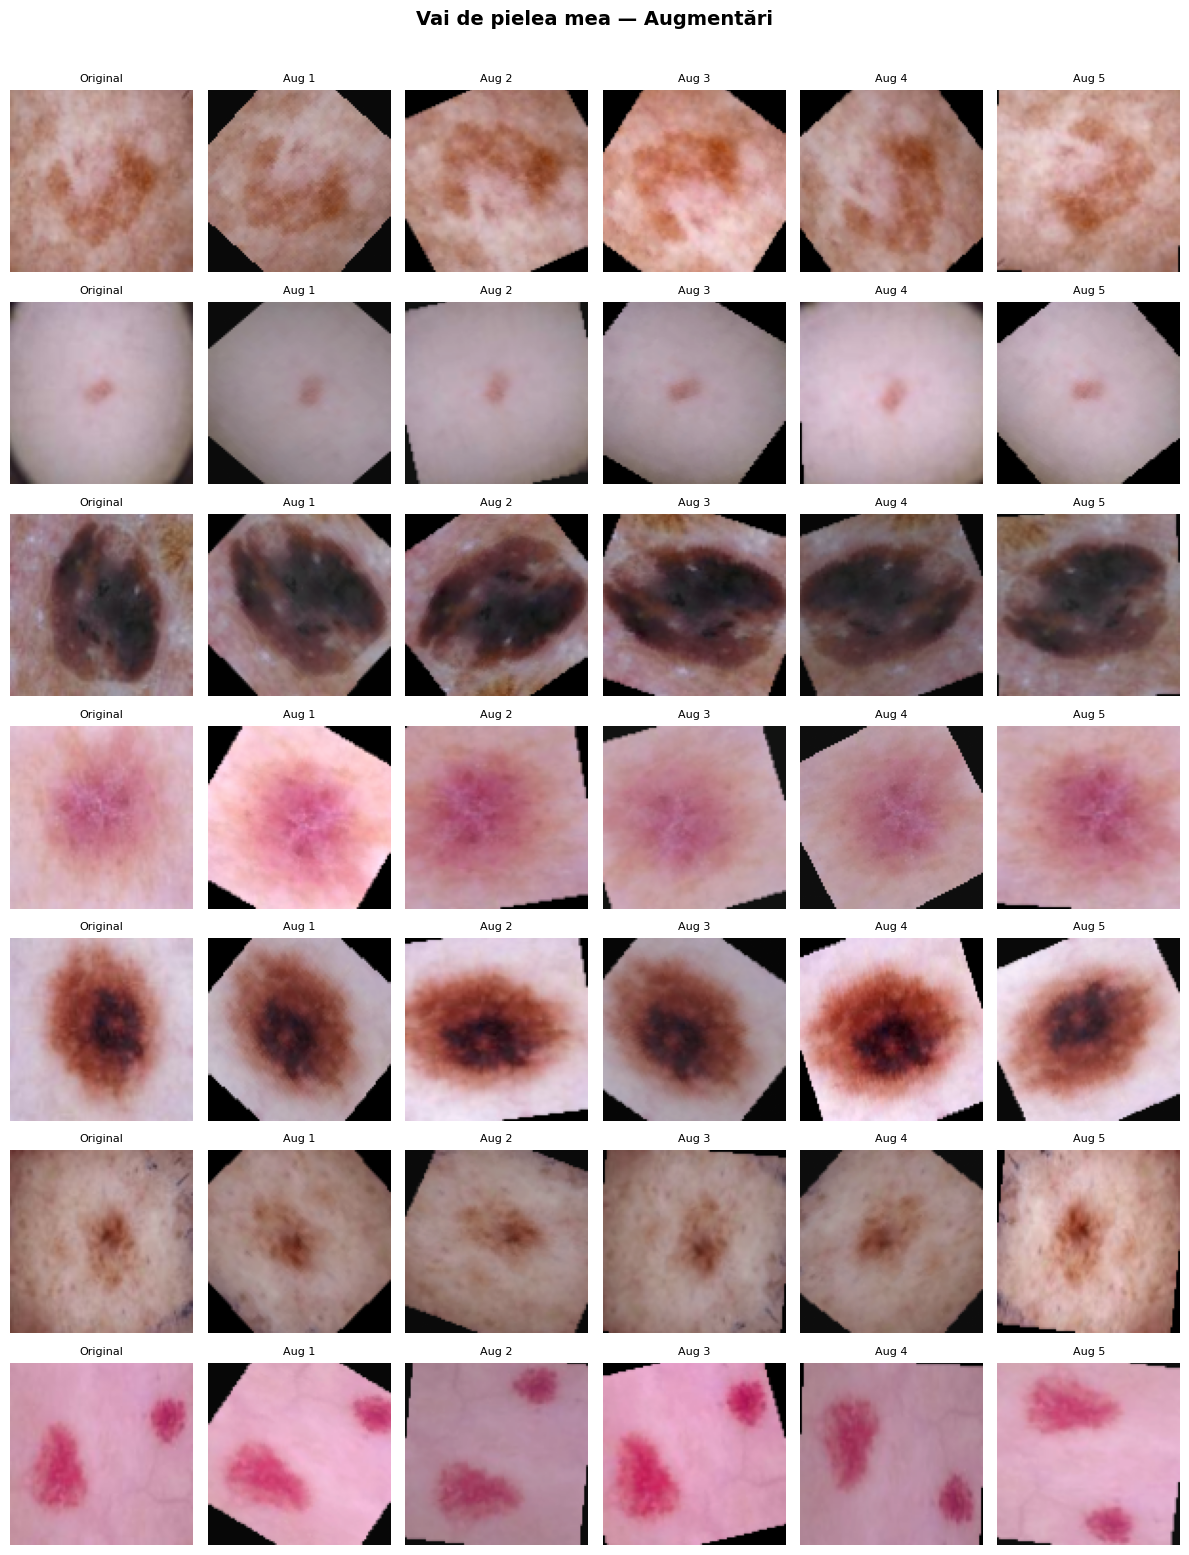

Salvat: Vai_de_pielea_mea_—_Augmentări_augmentations.png


In [7]:
# Dataset-uri pentru vizualizare (cu și fără augmentare)
mole_aug  = MoleDataset(os.path.join(MOLE_DIR, 'train.csv'), os.path.join(MOLE_DIR, 'train'), mole_train_transform)
mole_orig = MoleDataset(os.path.join(MOLE_DIR, 'train.csv'), os.path.join(MOLE_DIR, 'train'), mole_val_transform)

visualize_augmentations(
    dataset_aug=mole_aug,
    dataset_orig=mole_orig,
    idx2class=MOLE_IDX2CLASS,
    mean=MOLE_MEAN,
    std=MOLE_STD,
    title='Vai de pielea mea — Augmentări',
    n_aug=5
)

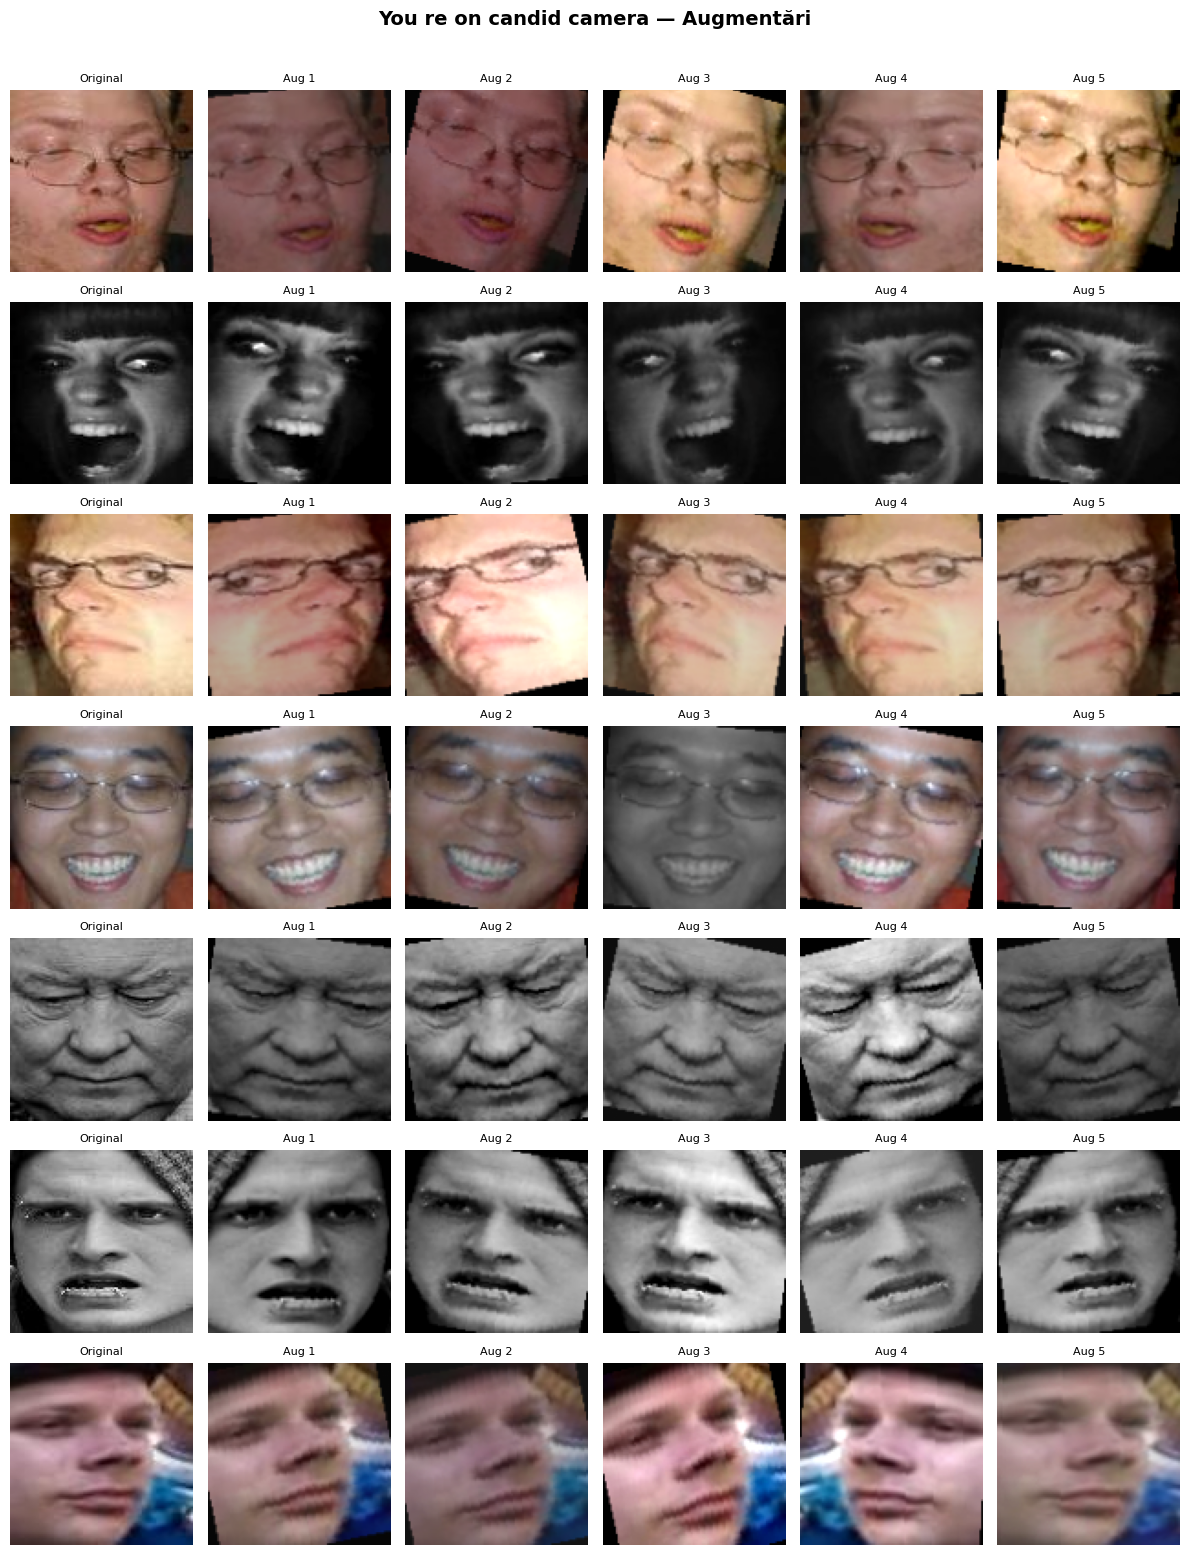

Salvat: You_re_on_candid_camera_—_Augmentări_augmentations.png


In [8]:
# Vizualizare augmentări pentru expresii faciale
face_aug  = FaceDataset(os.path.join(FACE_DIR, 'splits', 'train.csv'), FACE_DIR, face_train_transform)
face_orig = FaceDataset(os.path.join(FACE_DIR, 'splits', 'train.csv'), FACE_DIR, face_val_transform)

visualize_augmentations(
    dataset_aug=face_aug,
    dataset_orig=face_orig,
    idx2class=FACE_IDX2CLASS,
    mean=FACE_MEAN,
    std=FACE_STD,
    title='You re on candid camera — Augmentări',
    n_aug=5
)

---
## Pasul 1 — Pipeline de antrenare standard (MLP + CNN de bază)

In [9]:
# DataLoader-e complete pentru antrenare
BATCH_SIZE = 64

# --- Mole ---
mole_train_ds = MoleDataset(os.path.join(MOLE_DIR, 'train.csv'), os.path.join(MOLE_DIR, 'train'), mole_train_transform)
mole_val_ds   = MoleDataset(os.path.join(MOLE_DIR, 'test.csv'),  os.path.join(MOLE_DIR, 'test'),  mole_val_transform)

mole_train_loader = DataLoader(mole_train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, drop_last=True)
mole_val_loader   = DataLoader(mole_val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# --- Face ---
face_train_ds = FaceDataset(os.path.join(FACE_DIR, 'splits', 'train.csv'),      FACE_DIR, face_train_transform)
face_val_ds   = FaceDataset(os.path.join(FACE_DIR, 'splits', 'local_test.csv'), FACE_DIR, face_val_transform)

face_train_loader = DataLoader(face_train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, drop_last=True)
face_val_loader   = DataLoader(face_val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f'Mole  — train: {len(mole_train_ds)}, val: {len(mole_val_ds)}')
print(f'Face  — train: {len(face_train_ds)}, val: {len(face_val_ds)}')

Mole  — train: 6009, val: 2003
Face  — train: 10434, val: 1837


In [ ]:
#Arhitectura MLP
# Arhitectură: Flatten → Linear(in, 1024) → BN1d → ReLU → Dropout(0.4)
#              → Linear(1024, 512) → BN1d → ReLU → Dropout(0.3)
#              → Linear(512, 256) → BN1d → ReLU → Dropout(0.2)
#              → Linear(256, num_classes)
class MLP(nn.Module):
    def __init__(self, input_size, num_classes, use_dropout=True):
        super().__init__()
        layers = [
            nn.Flatten(),
            nn.Linear(input_size, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
        ]
        if use_dropout:
            layers.append(nn.Dropout(0.4))
        layers += [
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
        ]
        if use_dropout:
            layers.append(nn.Dropout(0.3))
        layers += [
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
        ]
        if use_dropout:
            layers.append(nn.Dropout(0.2))
        layers.append(nn.Linear(256, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

print('MLP definit.')

MLP definit.


In [ ]:
# Arhitectura CNN — comună ambelor seturi
# Restricții: max 4 straturi conv, max 2 Linear.
# Arhitectură:
#   Block1: Conv(3→32, 3×3) → BN → ReLU → MaxPool(2)       [48×48]
#   Block2: Conv(32→64, 3×3) → BN → ReLU → MaxPool(2)      [24×24]
#   Block3: Conv(64→128, 3×3) → BN → ReLU → MaxPool(2)     [12×12]
#   Block4: Conv(128→256, 3×3) → BN → ReLU
#   Global Average Pooling → (B, 256)
#   Dropout(0.5) → Linear(256, 128) → ReLU → Linear(128, num_classes)
class CNN(nn.Module):
    def __init__(self, num_classes, in_channels=3, first_kernel=3, use_batchnorm=True):
        super().__init__()
        pad = first_kernel // 2

        def conv_block(in_ch, out_ch, k=3, pool=True):
            layers = [nn.Conv2d(in_ch, out_ch, kernel_size=k, padding=k//2, bias=not use_batchnorm)]
            if use_batchnorm:
                layers.append(nn.BatchNorm2d(out_ch))
            layers.append(nn.ReLU(inplace=True))
            if pool:
                layers.append(nn.MaxPool2d(2))
            return layers

        self.features = nn.Sequential(
            *conv_block(in_channels, 32,  k=first_kernel, pool=True),   # conv 1
            *conv_block(32,          64,  k=3,            pool=True),   # conv 2
            *conv_block(64,          128, k=3,            pool=True),   # conv 3
            *conv_block(128,         256, k=3,            pool=False),  # conv 4
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes), 
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print('CNN definit.')

CNN definit.


In [ ]:
# Bucla de antrenare și evaluare (TensorBoard)
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        total_loss += loss.item() * images.size(0)
        preds = logits.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    avg_loss = total_loss / total
    acc = correct / total
    f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    return avg_loss, acc, f1_macro, all_preds, all_labels


def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler,
                num_epochs, run_name, device, verbose=True):
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, run_name))
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
               'val_f1_macro': []}
    best_f1 = 0.0

    for epoch in range(num_epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, va_f1m, _, _ = evaluate(model, val_loader, criterion, device)

        if scheduler is not None:
            scheduler.step()

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        history['val_f1_macro'].append(va_f1m)

        writer.add_scalar('Loss/train', tr_loss, epoch)
        writer.add_scalar('Loss/val',   va_loss, epoch)
        writer.add_scalar('Acc/train',  tr_acc,  epoch)
        writer.add_scalar('Acc/val',    va_acc,  epoch)
        writer.add_scalar('F1_macro/val', va_f1m, epoch)
        writer.add_scalar('LR', optimizer.param_groups[0]['lr'], epoch)

        if va_f1m > best_f1:
            best_f1 = va_f1m
            torch.save(model.state_dict(), f'{run_name}_best.pt')

        if verbose and (epoch + 1) % 5 == 0:
            print(f'Ep {epoch+1:03d} | '
                  f'tr_loss={tr_loss:.4f} tr_acc={tr_acc:.3f} | '
                  f'val_loss={va_loss:.4f} val_acc={va_acc:.3f} '
                  f'F1={va_f1m:.3f}')

    writer.close()
    print(f'Best val F1-macro: {best_f1:.4f} — model salvat în {run_name}_best.pt')
    return history


def plot_history(history, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(title, fontsize=13)
    axes[0].plot(history['train_loss'], label='train')
    axes[0].plot(history['val_loss'],   label='val')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epocă'); axes[0].legend()
    axes[1].plot(history['train_acc'], label='train')
    axes[1].plot(history['val_acc'],   label='val')
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epocă'); axes[1].legend()
    axes[2].plot(history['val_f1_macro'],  label='F1-macro')
    axes[2].set_title('F1 (val)'); axes[2].set_xlabel('Epocă'); axes[2].legend()
    plt.tight_layout()
    plt.savefig(f'{title.replace(" ", "_")}.png', dpi=100, bbox_inches='tight')
    plt.show()


def plot_confusion_matrix(model, loader, idx2class, device, title):
    _, _, _, preds, labels = evaluate(model, loader, nn.CrossEntropyLoss(), device)
    cm = confusion_matrix(labels, preds)
    class_names = [idx2class[i] for i in sorted(idx2class)]
    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicție'); ax.set_ylabel('Real')
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(f'{title.replace(" ", "_")}_cm.png', dpi=100)
    plt.show()
    print(classification_report(labels, preds, target_names=class_names, zero_division=0))

print('Funcții de antrenare/evaluare definite.')

Funcții de antrenare/evaluare definite.


---
## Pasul 4 — Tratarea dezechilibrului de clase (Secțiunea 4)

In [13]:
def get_class_weights(dataset, num_classes, device):
    labels = np.array([label for _, label in dataset.samples])
    counts = np.bincount(labels, minlength=num_classes).astype(float)
    weights = counts.sum() / (num_classes * counts)
    return torch.tensor(weights, dtype=torch.float).to(device)

def get_weighted_sampler(dataset, num_classes):
    labels = np.array([label for _, label in dataset.samples])
    counts = np.bincount(labels, minlength=num_classes).astype(float)
    class_w = 1.0 / counts
    sample_w = class_w[labels]
    return WeightedRandomSampler(
        weights=torch.from_numpy(sample_w).double(),
        num_samples=len(sample_w),
        replacement=True
    )

# Focal Loss
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.alpha, reduction='none')
        p_t = torch.exp(-ce)
        return ((1 - p_t) ** self.gamma * ce).mean()

print('Utilități dezechilibru clase definite.')

Utilități dezechilibru clase definite.


---
## 3.2 Antrenare MLP — ambele seturi de date

Mole class weights: [ 4.38   2.787  1.301 12.441  1.285  0.213 10.099]
Antrenare MLP pe Mole...
Ep 005 | tr_loss=1.0548 tr_acc=0.315 | val_loss=1.9650 val_acc=0.076 F1=0.085
Ep 010 | tr_loss=0.9169 tr_acc=0.368 | val_loss=1.8261 val_acc=0.153 F1=0.132
Ep 015 | tr_loss=0.8317 tr_acc=0.416 | val_loss=1.9950 val_acc=0.157 F1=0.124
Ep 020 | tr_loss=0.7640 tr_acc=0.446 | val_loss=1.7638 val_acc=0.267 F1=0.182
Ep 025 | tr_loss=0.7310 tr_acc=0.472 | val_loss=1.6223 val_acc=0.289 F1=0.228
Ep 030 | tr_loss=0.6686 tr_acc=0.487 | val_loss=1.6103 val_acc=0.272 F1=0.220
Best val F1-macro: 0.2276 — model salvat în mlp_mole_dropout_best.pt


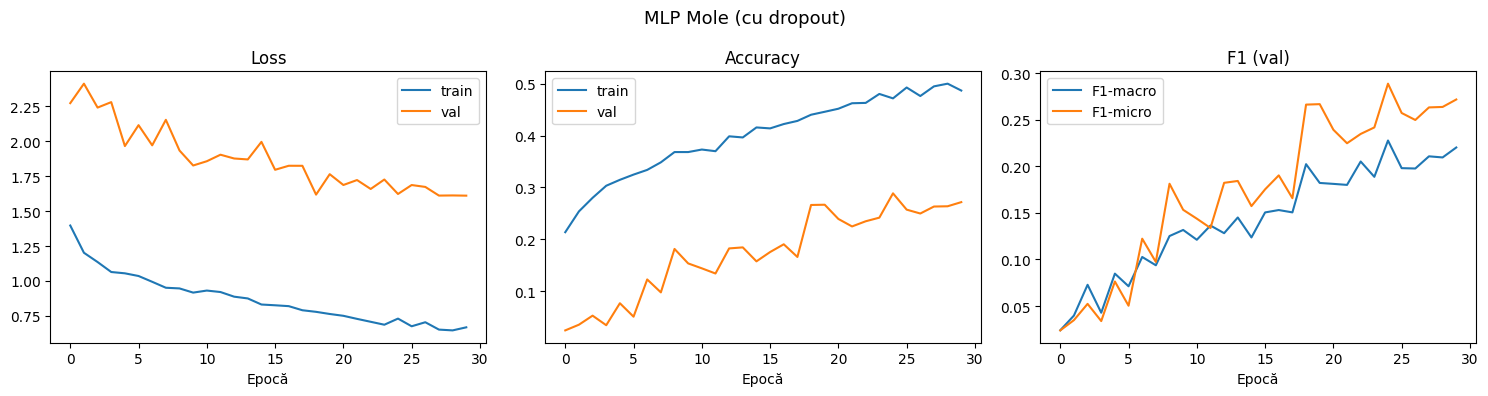

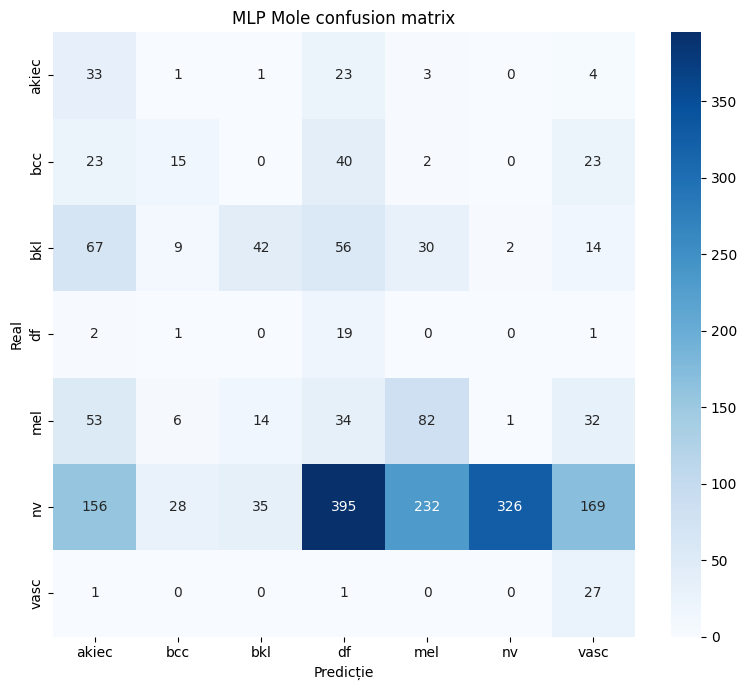

              precision    recall  f1-score   support

       akiec       0.10      0.51      0.17        65
         bcc       0.25      0.15      0.18       103
         bkl       0.46      0.19      0.27       220
          df       0.03      0.83      0.06        23
         mel       0.23      0.37      0.29       222
          nv       0.99      0.24      0.39      1341
        vasc       0.10      0.93      0.18        29

    accuracy                           0.27      2003
   macro avg       0.31      0.46      0.22      2003
weighted avg       0.76      0.27      0.34      2003



In [ ]:
# MLP pe Mole
NUM_CLASSES_MOLE = 7
# Imaginile sunt 96×96×3 după resize
INPUT_SIZE_MOLE = 3 * 96 * 96
NUM_EPOCHS_MLP = 30

# Ponderi pentru dezechilibru
mole_weights = get_class_weights(mole_train_ds, NUM_CLASSES_MOLE, device)
print('Mole class weights:', mole_weights.cpu().numpy().round(3))

# Sampler echilibrat
mole_sampler = get_weighted_sampler(mole_train_ds, NUM_CLASSES_MOLE)
mole_balanced_loader = DataLoader(mole_train_ds, batch_size=BATCH_SIZE,
                                   sampler=mole_sampler, num_workers=0, drop_last=True)

mlp_mole = MLP(INPUT_SIZE_MOLE, NUM_CLASSES_MOLE, use_dropout=True).to(device)
criterion_mole = nn.CrossEntropyLoss(weight=mole_weights)
optimizer_mlp_mole = optim.Adam(mlp_mole.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_mlp_mole = CosineAnnealingLR(optimizer_mlp_mole, T_max=NUM_EPOCHS_MLP)

print('Antrenare MLP pe Mole...')
hist_mlp_mole = train_model(
    mlp_mole, mole_balanced_loader, mole_val_loader,
    criterion_mole, optimizer_mlp_mole, scheduler_mlp_mole,
    NUM_EPOCHS_MLP, 'mlp_mole_dropout', device
)
plot_history(hist_mlp_mole, 'MLP Mole (cu dropout)')
plot_confusion_matrix(mlp_mole, mole_val_loader, MOLE_IDX2CLASS, device, 'MLP Mole confusion matrix')

Face class weights: [1.359 6.237 2.444 0.367 0.885 2.484 0.695]
Antrenare MLP pe Face...
Ep 005 | tr_loss=1.3038 tr_acc=0.282 | val_loss=2.4037 val_acc=0.132 F1=0.136
Ep 010 | tr_loss=1.2628 tr_acc=0.302 | val_loss=2.3462 val_acc=0.142 F1=0.136
Ep 015 | tr_loss=1.1944 tr_acc=0.331 | val_loss=2.1923 val_acc=0.167 F1=0.181
Ep 020 | tr_loss=1.1266 tr_acc=0.353 | val_loss=2.2160 val_acc=0.183 F1=0.190
Ep 025 | tr_loss=1.0320 tr_acc=0.388 | val_loss=2.1090 val_acc=0.217 F1=0.217
Ep 030 | tr_loss=0.9771 tr_acc=0.418 | val_loss=2.0836 val_acc=0.220 F1=0.225
Best val F1-macro: 0.2252 — model salvat în mlp_face_dropout_best.pt


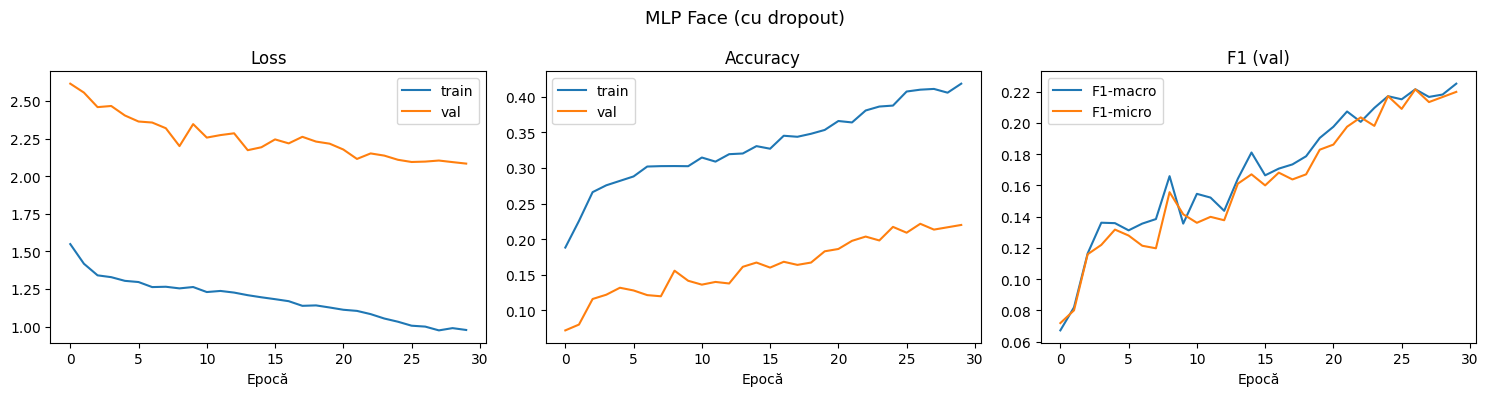

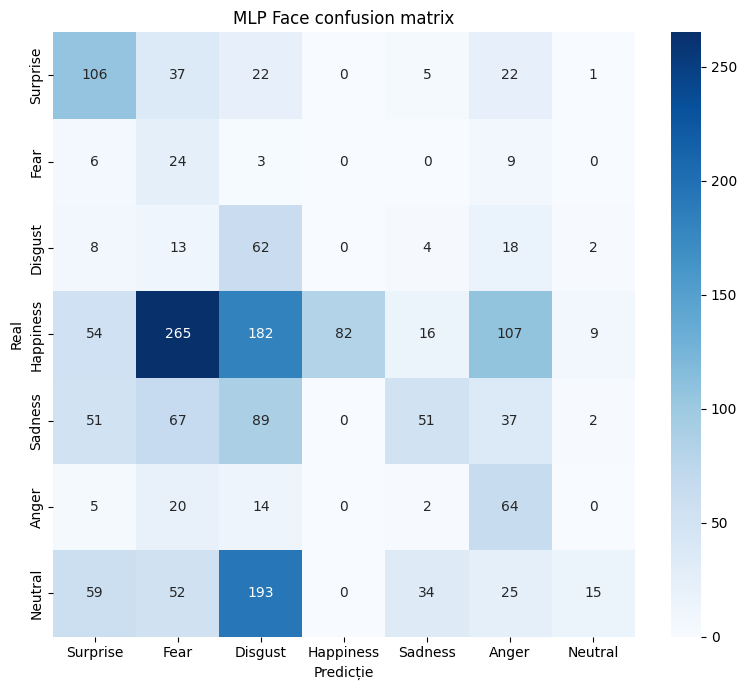

              precision    recall  f1-score   support

    Surprise       0.37      0.55      0.44       193
        Fear       0.05      0.57      0.09        42
     Disgust       0.11      0.58      0.18       107
   Happiness       1.00      0.11      0.21       715
     Sadness       0.46      0.17      0.25       297
       Anger       0.23      0.61      0.33       105
     Neutral       0.52      0.04      0.07       378

    accuracy                           0.22      1837
   macro avg       0.39      0.38      0.23      1837
weighted avg       0.63      0.22      0.21      1837



In [15]:
# ==================== MLP pe Face ====================
NUM_CLASSES_FACE = 7
INPUT_SIZE_FACE = 3 * 100 * 100

face_weights = get_class_weights(face_train_ds, NUM_CLASSES_FACE, device)
print('Face class weights:', face_weights.cpu().numpy().round(3))

face_sampler = get_weighted_sampler(face_train_ds, NUM_CLASSES_FACE)
face_balanced_loader = DataLoader(face_train_ds, batch_size=BATCH_SIZE,
                                   sampler=face_sampler, num_workers=0, drop_last=True)

mlp_face = MLP(INPUT_SIZE_FACE, NUM_CLASSES_FACE, use_dropout=True).to(device)
criterion_face = nn.CrossEntropyLoss(weight=face_weights)
optimizer_mlp_face = optim.Adam(mlp_face.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_mlp_face = CosineAnnealingLR(optimizer_mlp_face, T_max=NUM_EPOCHS_MLP)

print('Antrenare MLP pe Face...')
hist_mlp_face = train_model(
    mlp_face, face_balanced_loader, face_val_loader,
    criterion_face, optimizer_mlp_face, scheduler_mlp_face,
    NUM_EPOCHS_MLP, 'mlp_face_dropout', device
)
plot_history(hist_mlp_face, 'MLP Face (cu dropout)')
plot_confusion_matrix(mlp_face, face_val_loader, FACE_IDX2CLASS, device, 'MLP Face confusion matrix')

---
## 3.5 Ablație MLP: cu vs fără Dropout

Antrenare MLP Mole fără dropout...
Ep 005 | tr_loss=0.9600 tr_acc=0.353 | val_loss=1.8998 val_acc=0.114 F1=0.131
Ep 010 | tr_loss=0.8037 tr_acc=0.445 | val_loss=1.9304 val_acc=0.138 F1=0.143
Ep 015 | tr_loss=0.6553 tr_acc=0.509 | val_loss=1.7157 val_acc=0.268 F1=0.219
Ep 020 | tr_loss=0.5079 tr_acc=0.573 | val_loss=1.6380 val_acc=0.257 F1=0.241
Ep 025 | tr_loss=0.4202 tr_acc=0.618 | val_loss=1.4377 val_acc=0.381 F1=0.285
Ep 030 | tr_loss=0.3945 tr_acc=0.638 | val_loss=1.4402 val_acc=0.375 F1=0.285
Best val F1-macro: 0.3050 — model salvat în mlp_mole_nodropout_best.pt


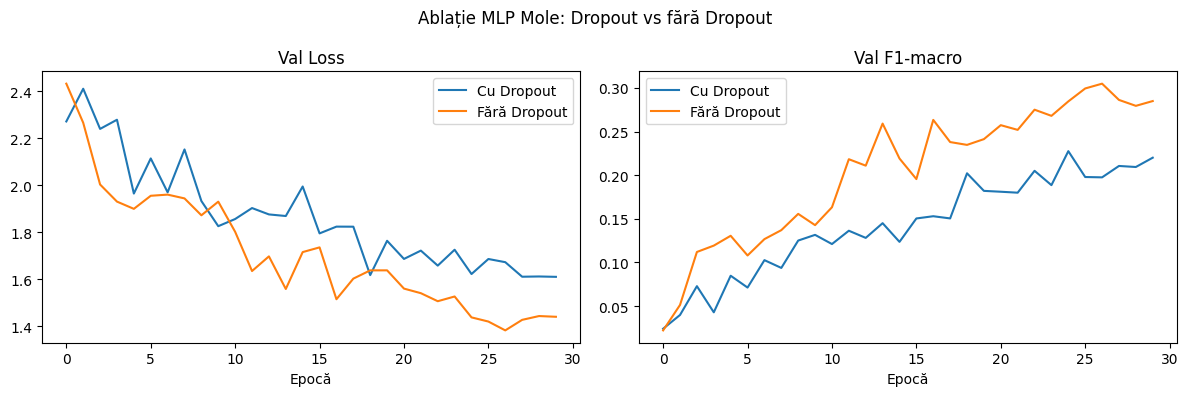

In [ ]:
# MLP fără dropout — Mole
mlp_mole_nodrop = MLP(INPUT_SIZE_MOLE, NUM_CLASSES_MOLE, use_dropout=False).to(device)
opt_nd_mole = optim.Adam(mlp_mole_nodrop.parameters(), lr=1e-3, weight_decay=1e-4)
sched_nd_mole = CosineAnnealingLR(opt_nd_mole, T_max=NUM_EPOCHS_MLP)

print('Antrenare MLP Mole fără dropout...')
hist_mlp_mole_nd = train_model(
    mlp_mole_nodrop, mole_balanced_loader, mole_val_loader,
    criterion_mole, opt_nd_mole, sched_nd_mole,
    NUM_EPOCHS_MLP, 'mlp_mole_nodropout', device
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Ablație MLP Mole: Dropout vs fără Dropout')
for ax, key, ylabel in zip(axes, ['val_loss', 'val_f1_macro'], ['Val Loss', 'Val F1-macro']):
    ax.plot(hist_mlp_mole[key],    label='Cu Dropout')
    ax.plot(hist_mlp_mole_nd[key], label='Fără Dropout')
    ax.set_title(ylabel); ax.set_xlabel('Epocă'); ax.legend()
plt.tight_layout()
plt.savefig('ablatie_mlp_dropout_mole.png', dpi=100)
plt.show()

Antrenare MLP Face fără dropout...
Ep 005 | tr_loss=1.2423 tr_acc=0.312 | val_loss=2.4413 val_acc=0.133 F1=0.142
Ep 010 | tr_loss=1.1429 tr_acc=0.360 | val_loss=2.3061 val_acc=0.192 F1=0.195
Ep 015 | tr_loss=1.0291 tr_acc=0.404 | val_loss=2.0707 val_acc=0.238 F1=0.233
Ep 020 | tr_loss=0.9102 tr_acc=0.460 | val_loss=2.0279 val_acc=0.275 F1=0.266
Ep 025 | tr_loss=0.7572 tr_acc=0.520 | val_loss=1.9165 val_acc=0.319 F1=0.304
Ep 030 | tr_loss=0.6960 tr_acc=0.549 | val_loss=1.9034 val_acc=0.326 F1=0.305
Best val F1-macro: 0.3100 — model salvat în mlp_face_nodropout_best.pt


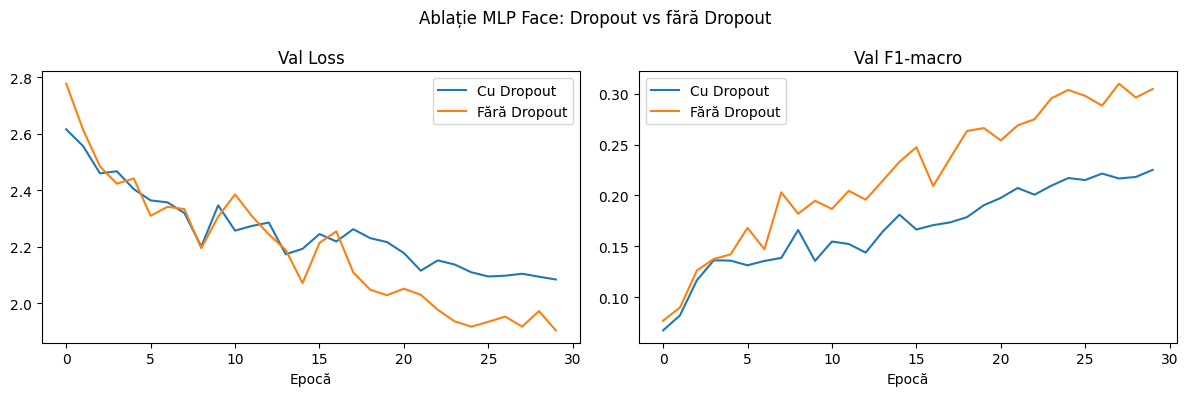

In [17]:
# MLP fără dropout — Face
mlp_face_nodrop = MLP(INPUT_SIZE_FACE, NUM_CLASSES_FACE, use_dropout=False).to(device)
opt_nd_face = optim.Adam(mlp_face_nodrop.parameters(), lr=1e-3, weight_decay=1e-4)
sched_nd_face = CosineAnnealingLR(opt_nd_face, T_max=NUM_EPOCHS_MLP)

print('Antrenare MLP Face fără dropout...')
hist_mlp_face_nd = train_model(
    mlp_face_nodrop, face_balanced_loader, face_val_loader,
    criterion_face, opt_nd_face, sched_nd_face,
    NUM_EPOCHS_MLP, 'mlp_face_nodropout', device
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Ablație MLP Face: Dropout vs fără Dropout')
for ax, key, ylabel in zip(axes, ['val_loss', 'val_f1_macro'], ['Val Loss', 'Val F1-macro']):
    ax.plot(hist_mlp_face[key],    label='Cu Dropout')
    ax.plot(hist_mlp_face_nd[key], label='Fără Dropout')
    ax.set_title(ylabel); ax.set_xlabel('Epocă'); ax.legend()
plt.tight_layout()
plt.savefig('ablatie_mlp_dropout_face.png', dpi=100)
plt.show()

---
## 3.3 Antrenare CNN — ambele seturi

Antrenare CNN pe Mole (cu BatchNorm)...
Ep 005 | tr_loss=0.8974 tr_acc=0.366 | val_loss=2.3443 val_acc=0.057 F1=0.082
Ep 010 | tr_loss=0.7554 tr_acc=0.430 | val_loss=1.6449 val_acc=0.139 F1=0.168
Ep 015 | tr_loss=0.6511 tr_acc=0.474 | val_loss=1.5543 val_acc=0.192 F1=0.249
Ep 020 | tr_loss=0.5887 tr_acc=0.525 | val_loss=1.5299 val_acc=0.229 F1=0.237
Ep 025 | tr_loss=0.5099 tr_acc=0.564 | val_loss=1.4538 val_acc=0.268 F1=0.259
Ep 030 | tr_loss=0.5031 tr_acc=0.567 | val_loss=1.4064 val_acc=0.275 F1=0.272
Best val F1-macro: 0.2927 — model salvat în cnn_mole_bn_best.pt


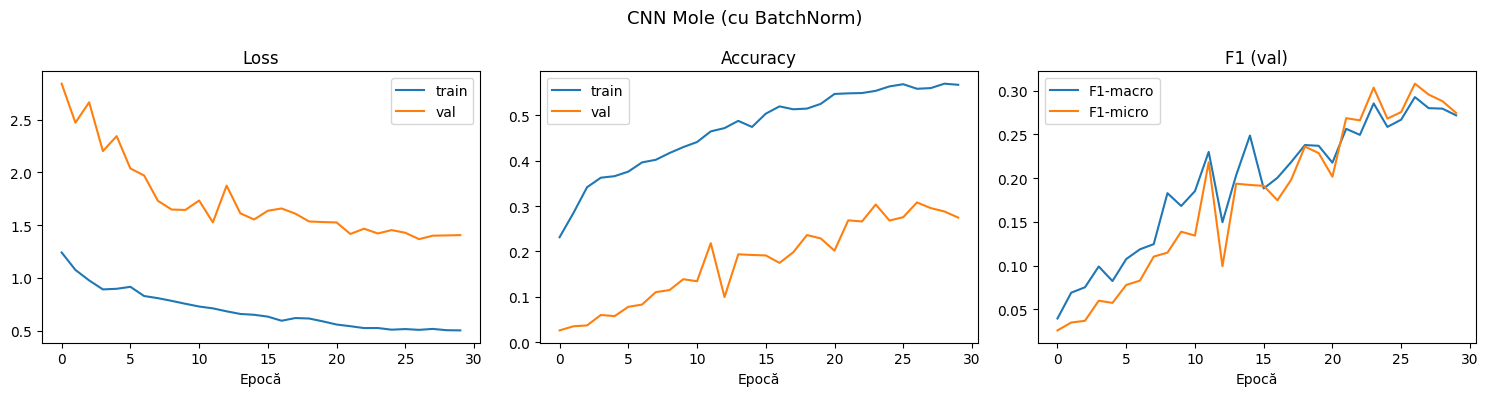

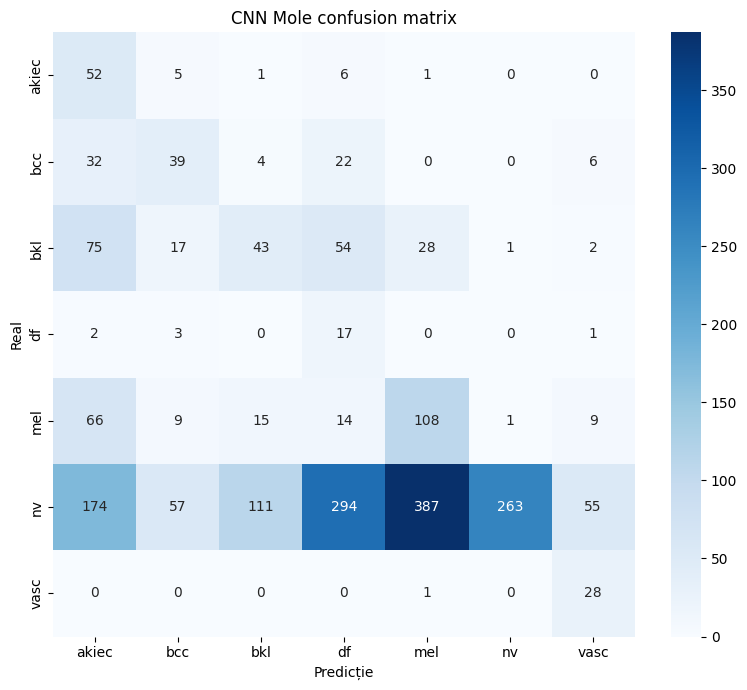

              precision    recall  f1-score   support

       akiec       0.13      0.80      0.22        65
         bcc       0.30      0.38      0.33       103
         bkl       0.25      0.20      0.22       220
          df       0.04      0.74      0.08        23
         mel       0.21      0.49      0.29       222
          nv       0.99      0.20      0.33      1341
        vasc       0.28      0.97      0.43        29

    accuracy                           0.27      2003
   macro avg       0.31      0.54      0.27      2003
weighted avg       0.74      0.27      0.31      2003



In [18]:
NUM_EPOCHS_CNN = 50

# CNN pe Mole (primul kernel 5×5 pentru receptive field mai mare)
cnn_mole = CNN(NUM_CLASSES_MOLE, first_kernel=5, use_batchnorm=True).to(device)
opt_cnn_mole = optim.Adam(cnn_mole.parameters(), lr=1e-3, weight_decay=1e-4)
sched_cnn_mole = CosineAnnealingLR(opt_cnn_mole, T_max=NUM_EPOCHS_CNN)

print('Antrenare CNN pe Mole (cu BatchNorm)...')
hist_cnn_mole = train_model(
    cnn_mole, mole_balanced_loader, mole_val_loader,
    criterion_mole, opt_cnn_mole, sched_cnn_mole,
    NUM_EPOCHS_CNN, 'cnn_mole_bn', device
)
plot_history(hist_cnn_mole, 'CNN Mole (cu BatchNorm)')
plot_confusion_matrix(cnn_mole, mole_val_loader, MOLE_IDX2CLASS, device, 'CNN Mole confusion matrix')


Antrenare CNN pe Face (cu BatchNorm)...
Ep 005 | tr_loss=1.4379 tr_acc=0.206 | val_loss=2.9258 val_acc=0.044 F1=0.051
Ep 010 | tr_loss=1.2823 tr_acc=0.287 | val_loss=2.2126 val_acc=0.120 F1=0.127
Ep 015 | tr_loss=1.1531 tr_acc=0.329 | val_loss=2.8539 val_acc=0.102 F1=0.096
Ep 020 | tr_loss=1.0242 tr_acc=0.376 | val_loss=2.4572 val_acc=0.127 F1=0.144
Ep 025 | tr_loss=0.9454 tr_acc=0.409 | val_loss=2.2161 val_acc=0.165 F1=0.196
Ep 030 | tr_loss=0.8922 tr_acc=0.433 | val_loss=2.3357 val_acc=0.160 F1=0.183
Best val F1-macro: 0.1964 — model salvat în cnn_face_bn_best.pt


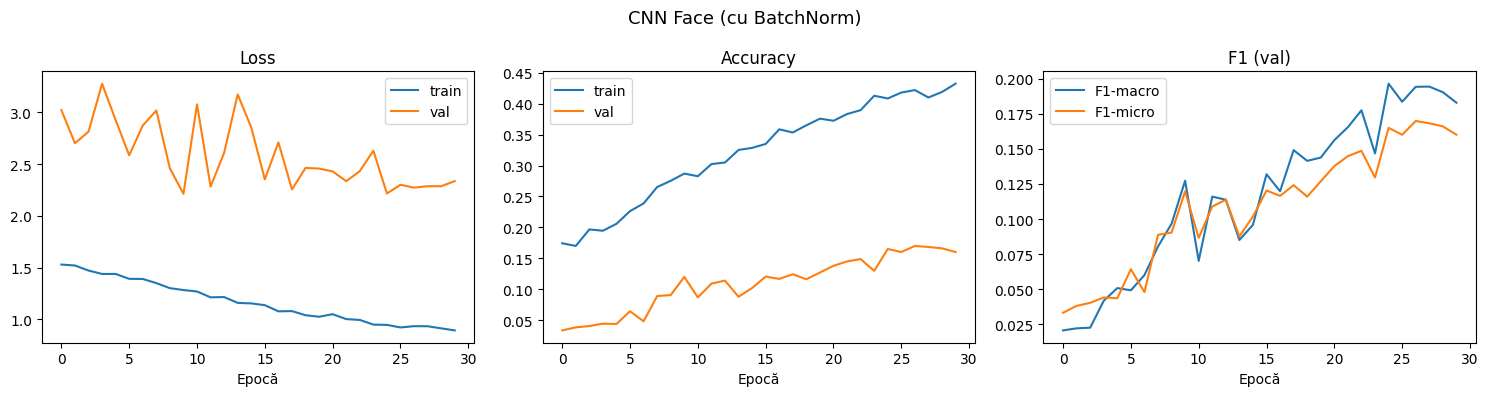

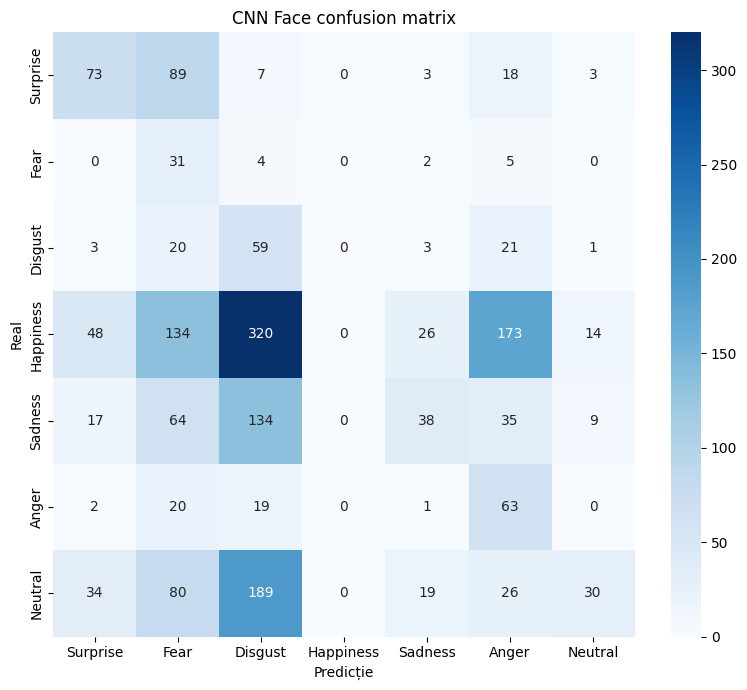

              precision    recall  f1-score   support

    Surprise       0.41      0.38      0.39       193
        Fear       0.07      0.74      0.13        42
     Disgust       0.08      0.55      0.14       107
   Happiness       0.00      0.00      0.00       715
     Sadness       0.41      0.13      0.20       297
       Anger       0.18      0.60      0.28       105
     Neutral       0.53      0.08      0.14       378

    accuracy                           0.16      1837
   macro avg       0.24      0.35      0.18      1837
weighted avg       0.24      0.16      0.13      1837



In [19]:
# CNN pe Face (primul kernel 3×3)
cnn_face = CNN(NUM_CLASSES_FACE, first_kernel=3, use_batchnorm=True).to(device)
opt_cnn_face = optim.Adam(cnn_face.parameters(), lr=1e-3, weight_decay=1e-4)
sched_cnn_face = CosineAnnealingLR(opt_cnn_face, T_max=NUM_EPOCHS_CNN)

print('Antrenare CNN pe Face (cu BatchNorm)...')
hist_cnn_face = train_model(
    cnn_face, face_balanced_loader, face_val_loader,
    criterion_face, opt_cnn_face, sched_cnn_face,
    NUM_EPOCHS_CNN, 'cnn_face_bn', device
)
plot_history(hist_cnn_face, 'CNN Face (cu BatchNorm)')
plot_confusion_matrix(cnn_face, face_val_loader, FACE_IDX2CLASS, device, 'CNN Face confusion matrix')


---
## 3.5 Ablație CNN: cu vs fără BatchNorm

Antrenare CNN Mole fără BatchNorm...
Ep 005 | tr_loss=1.0411 tr_acc=0.290 | val_loss=1.9525 val_acc=0.073 F1=0.095
Ep 010 | tr_loss=0.8531 tr_acc=0.378 | val_loss=1.7292 val_acc=0.081 F1=0.120
Ep 015 | tr_loss=0.7073 tr_acc=0.453 | val_loss=1.7320 val_acc=0.130 F1=0.150
Ep 020 | tr_loss=0.6128 tr_acc=0.500 | val_loss=1.6155 val_acc=0.144 F1=0.177
Ep 025 | tr_loss=0.5349 tr_acc=0.532 | val_loss=1.5177 val_acc=0.177 F1=0.203
Ep 030 | tr_loss=0.5337 tr_acc=0.541 | val_loss=1.4810 val_acc=0.227 F1=0.223
Best val F1-macro: 0.2229 — model salvat în cnn_mole_nobn_best.pt


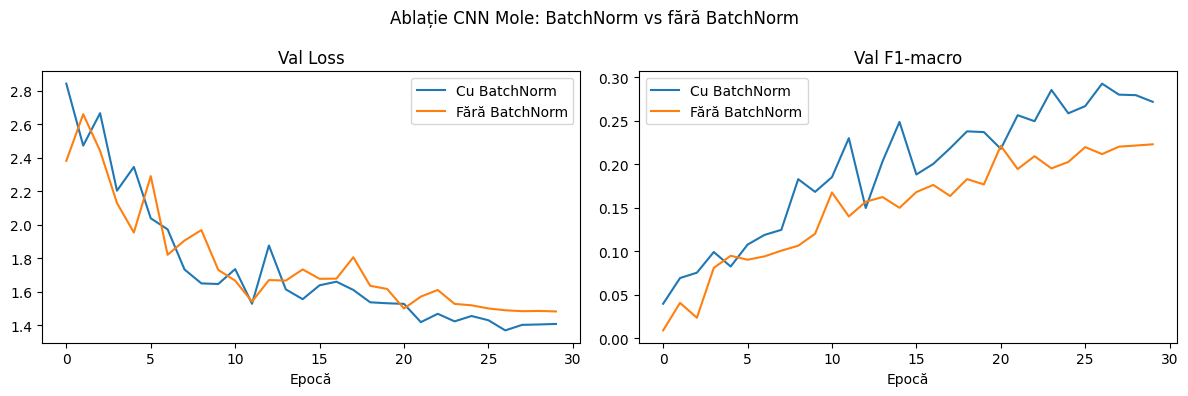

In [20]:
# CNN fără BatchNorm — Mole
cnn_mole_nobn = CNN(NUM_CLASSES_MOLE, first_kernel=5, use_batchnorm=False).to(device)
opt_nobn_mole = optim.Adam(cnn_mole_nobn.parameters(), lr=1e-3, weight_decay=1e-4)
sched_nobn_mole = CosineAnnealingLR(opt_nobn_mole, T_max=NUM_EPOCHS_CNN)

print('Antrenare CNN Mole fără BatchNorm...')
hist_cnn_mole_nobn = train_model(
    cnn_mole_nobn, mole_balanced_loader, mole_val_loader,
    criterion_mole, opt_nobn_mole, sched_nobn_mole,
    NUM_EPOCHS_CNN, 'cnn_mole_nobn', device
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Ablație CNN Mole: BatchNorm vs fără BatchNorm')
for ax, key, ylabel in zip(axes, ['val_loss', 'val_f1_macro'], ['Val Loss', 'Val F1-macro']):
    ax.plot(hist_cnn_mole[key],      label='Cu BatchNorm')
    ax.plot(hist_cnn_mole_nobn[key], label='Fără BatchNorm')
    ax.set_title(ylabel); ax.set_xlabel('Epocă'); ax.legend()
plt.tight_layout()
plt.savefig('ablatie_cnn_batchnorm_mole.png', dpi=100)
plt.show()

Antrenare CNN Face fără BatchNorm...
Ep 005 | tr_loss=1.4943 tr_acc=0.181 | val_loss=2.6683 val_acc=0.039 F1=0.022
Ep 010 | tr_loss=1.4410 tr_acc=0.201 | val_loss=2.8805 val_acc=0.046 F1=0.039
Ep 015 | tr_loss=1.3065 tr_acc=0.262 | val_loss=2.6844 val_acc=0.076 F1=0.058
Ep 020 | tr_loss=1.2003 tr_acc=0.292 | val_loss=2.5430 val_acc=0.087 F1=0.075
Ep 025 | tr_loss=1.1356 tr_acc=0.307 | val_loss=2.5060 val_acc=0.088 F1=0.078
Ep 030 | tr_loss=1.1172 tr_acc=0.317 | val_loss=2.4731 val_acc=0.093 F1=0.082
Best val F1-macro: 0.0995 — model salvat în cnn_face_nobn_best.pt


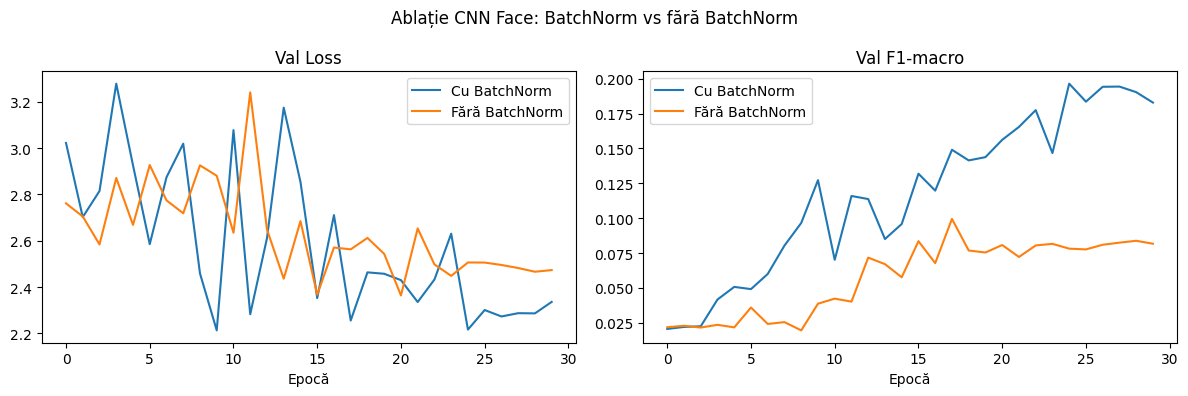

In [21]:
# CNN fără BatchNorm — Face
cnn_face_nobn = CNN(NUM_CLASSES_FACE, first_kernel=3, use_batchnorm=False).to(device)
opt_nobn_face = optim.Adam(cnn_face_nobn.parameters(), lr=1e-3, weight_decay=1e-4)
sched_nobn_face = CosineAnnealingLR(opt_nobn_face, T_max=NUM_EPOCHS_CNN)

print('Antrenare CNN Face fără BatchNorm...')
hist_cnn_face_nobn = train_model(
    cnn_face_nobn, face_balanced_loader, face_val_loader,
    criterion_face, opt_nobn_face, sched_nobn_face,
    NUM_EPOCHS_CNN, 'cnn_face_nobn', device
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Ablație CNN Face: BatchNorm vs fără BatchNorm')
for ax, key, ylabel in zip(axes, ['val_loss', 'val_f1_macro'], ['Val Loss', 'Val F1-macro']):
    ax.plot(hist_cnn_face[key],      label='Cu BatchNorm')
    ax.plot(hist_cnn_face_nobn[key], label='Fără BatchNorm')
    ax.set_title(ylabel); ax.set_xlabel('Epocă'); ax.legend()
plt.tight_layout()
plt.savefig('ablatie_cnn_batchnorm_face.png', dpi=100)
plt.show()

---
## 3.5 Ablație CNN: configurații de augmentare

In [22]:
# Definim cele 4 configurații de augmentare cerute
def make_mole_transform(geometric=False, color=False):
    base = [transforms.Resize((96, 96))]
    if geometric:
        base += [
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.5),
            transforms.RandomRotation(degrees=180),
            transforms.RandomResizedCrop(size=96, scale=(0.85, 1.0)),
        ]
    if color:
        base += [
            transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
        ]
    base += [transforms.ToTensor(), transforms.Normalize(mean=MOLE_MEAN, std=MOLE_STD)]
    return transforms.Compose(base)

aug_configs_mole = {
    'fără augmentări':                  make_mole_transform(False, False),
    'augmentări geometrice':            make_mole_transform(True,  False),
    'augmentări culoare':               make_mole_transform(False, True),
    'toate augmentările':               make_mole_transform(True,  True),
}

print('Configurații augmentare definite:', list(aug_configs_mole.keys()))

Configurații augmentare definite: ['fără augmentări', 'augmentări geometrice', 'augmentări culoare', 'toate augmentările']



Antrenare CNN Mole — fără augmentări...
Ep 005 | tr_loss=0.6513 tr_acc=0.471 | val_loss=2.0427 val_acc=0.103 F1=0.127
Ep 010 | tr_loss=0.4351 tr_acc=0.584 | val_loss=1.5198 val_acc=0.263 F1=0.273
Ep 015 | tr_loss=0.3105 tr_acc=0.658 | val_loss=1.6581 val_acc=0.260 F1=0.284
Ep 020 | tr_loss=0.2337 tr_acc=0.718 | val_loss=1.2834 val_acc=0.436 F1=0.374
Ep 025 | tr_loss=0.2136 tr_acc=0.739 | val_loss=1.3578 val_acc=0.431 F1=0.392
Ep 030 | tr_loss=0.2072 tr_acc=0.741 | val_loss=1.1631 val_acc=0.479 F1=0.434
Best val F1-macro: 0.4479 — model salvat în cnn_mole_aug_fără_augmentări_best.pt

Antrenare CNN Mole — augmentări geometrice...
Ep 005 | tr_loss=0.7634 tr_acc=0.430 | val_loss=1.8739 val_acc=0.118 F1=0.183
Ep 010 | tr_loss=0.6411 tr_acc=0.489 | val_loss=1.5865 val_acc=0.156 F1=0.195
Ep 015 | tr_loss=0.5561 tr_acc=0.545 | val_loss=1.3880 val_acc=0.267 F1=0.259
Ep 020 | tr_loss=0.4470 tr_acc=0.597 | val_loss=1.4451 val_acc=0.264 F1=0.270
Ep 025 | tr_loss=0.4164 tr_acc=0.609 | val_loss=1.3

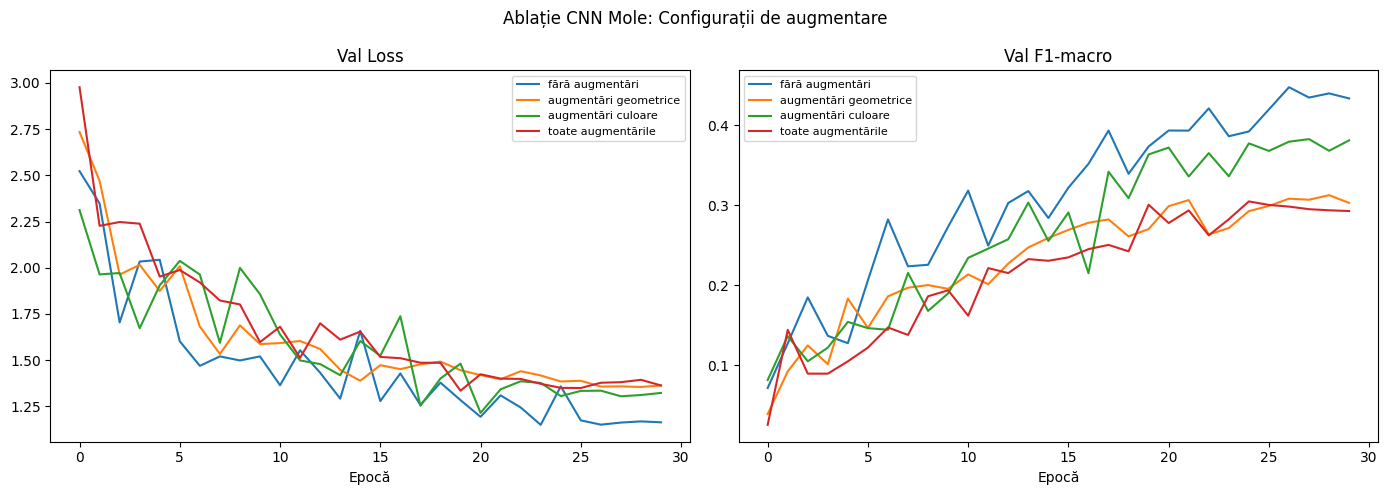

In [23]:
hist_aug_mole = {}

for config_name, transform in aug_configs_mole.items():
    print(f'\nAntrenare CNN Mole — {config_name}...')
    ds = MoleDataset(os.path.join(MOLE_DIR, 'train.csv'), os.path.join(MOLE_DIR, 'train'), transform)
    sampler = get_weighted_sampler(ds, NUM_CLASSES_MOLE)
    loader = DataLoader(ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0, drop_last=True)

    model = CNN(NUM_CLASSES_MOLE, first_kernel=5, use_batchnorm=True).to(device)
    opt   = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = CosineAnnealingLR(opt, T_max=NUM_EPOCHS_CNN)
    run_id = config_name.replace(' ', '_')

    hist = train_model(model, loader, mole_val_loader,
                       criterion_mole, opt, sched,
                       NUM_EPOCHS_CNN, f'cnn_mole_aug_{run_id}', device)
    hist_aug_mole[config_name] = hist

# Grafic comparativ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Ablație CNN Mole: Configurații de augmentare')
for config_name, hist in hist_aug_mole.items():
    axes[0].plot(hist['val_loss'],     label=config_name)
    axes[1].plot(hist['val_f1_macro'], label=config_name)
axes[0].set_title('Val Loss');     axes[0].set_xlabel('Epocă'); axes[0].legend(fontsize=8)
axes[1].set_title('Val F1-macro'); axes[1].set_xlabel('Epocă'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('ablatie_augmentare_mole.png', dpi=100)
plt.show()


Antrenare CNN Face — fără augmentări...
Ep 005 | tr_loss=1.1973 tr_acc=0.316 | val_loss=2.2530 val_acc=0.108 F1=0.117
Ep 010 | tr_loss=0.8552 tr_acc=0.426 | val_loss=2.6994 val_acc=0.119 F1=0.107
Ep 015 | tr_loss=0.6145 tr_acc=0.532 | val_loss=2.1812 val_acc=0.224 F1=0.253
Ep 020 | tr_loss=0.4265 tr_acc=0.636 | val_loss=3.1397 val_acc=0.148 F1=0.187
Ep 025 | tr_loss=0.3198 tr_acc=0.701 | val_loss=2.0485 val_acc=0.290 F1=0.295
Ep 030 | tr_loss=0.2969 tr_acc=0.719 | val_loss=1.9910 val_acc=0.322 F1=0.311
Best val F1-macro: 0.3109 — model salvat în cnn_face_aug_fără_augmentări_best.pt

Antrenare CNN Face — augmentări geometrice...
Ep 005 | tr_loss=1.3906 tr_acc=0.237 | val_loss=2.9100 val_acc=0.087 F1=0.080
Ep 010 | tr_loss=1.1709 tr_acc=0.326 | val_loss=2.9017 val_acc=0.084 F1=0.091
Ep 015 | tr_loss=1.0497 tr_acc=0.379 | val_loss=2.4727 val_acc=0.152 F1=0.172
Ep 020 | tr_loss=0.9057 tr_acc=0.436 | val_loss=2.2617 val_acc=0.183 F1=0.208
Ep 025 | tr_loss=0.7961 tr_acc=0.472 | val_loss=2.0

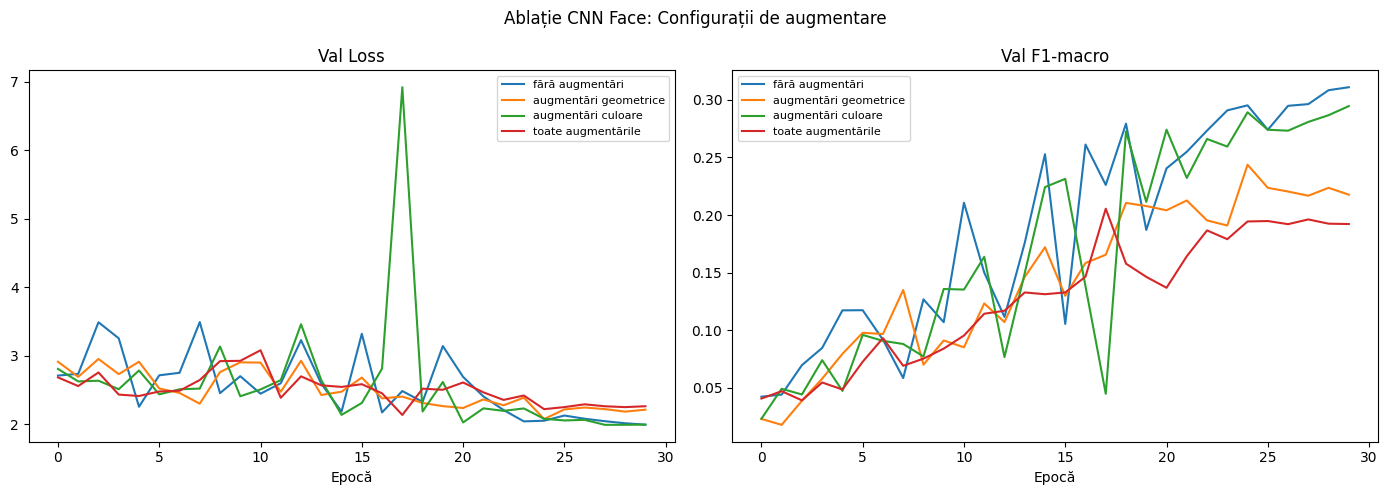

In [24]:
# Același experiment pe Face
def make_face_transform(geometric=False, color=False):
    base = [transforms.Resize((112, 112))]
    if geometric:
        base += [
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=15),
            transforms.RandomResizedCrop(size=100, scale=(0.85, 1.0)),
        ]
    else:
        base.append(transforms.CenterCrop(100))
    if color:
        base += [
            transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
            transforms.RandomGrayscale(p=0.05),
        ]
    base += [transforms.ToTensor(), transforms.Normalize(mean=FACE_MEAN, std=FACE_STD)]
    return transforms.Compose(base)

aug_configs_face = {
    'fără augmentări':       make_face_transform(False, False),
    'augmentări geometrice': make_face_transform(True,  False),
    'augmentări culoare':    make_face_transform(False, True),
    'toate augmentările':    make_face_transform(True,  True),
}

hist_aug_face = {}
for config_name, transform in aug_configs_face.items():
    print(f'\nAntrenare CNN Face — {config_name}...')
    ds = FaceDataset(os.path.join(FACE_DIR, 'splits', 'train.csv'), FACE_DIR, transform)
    sampler = get_weighted_sampler(ds, NUM_CLASSES_FACE)
    loader = DataLoader(ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0, drop_last=True)
    model = CNN(NUM_CLASSES_FACE, first_kernel=3, use_batchnorm=True).to(device)
    opt   = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = CosineAnnealingLR(opt, T_max=NUM_EPOCHS_CNN)
    hist  = train_model(model, loader, face_val_loader,
                        criterion_face, opt, sched,
                        NUM_EPOCHS_CNN, f'cnn_face_aug_{config_name.replace(" ","_")}', device)
    hist_aug_face[config_name] = hist

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Ablație CNN Face: Configurații de augmentare')
for config_name, hist in hist_aug_face.items():
    axes[0].plot(hist['val_loss'],     label=config_name)
    axes[1].plot(hist['val_f1_macro'], label=config_name)
axes[0].set_title('Val Loss');     axes[0].set_xlabel('Epocă'); axes[0].legend(fontsize=8)
axes[1].set_title('Val F1-macro'); axes[1].set_xlabel('Epocă'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('ablatie_augmentare_face.png', dpi=100)
plt.show()

---
## 3.5 Ablație: cu vs fără tehnici de rezolvare a dezechilibrului


Ablație dezechilibru — Mole:
  fără echilibrare...
Ep 005 | tr_loss=0.8117 tr_acc=0.700 | val_loss=0.8211 val_acc=0.702 F1=0.285
Ep 010 | tr_loss=0.7694 tr_acc=0.711 | val_loss=0.7469 val_acc=0.724 F1=0.360
Ep 015 | tr_loss=0.7204 tr_acc=0.731 | val_loss=0.7206 val_acc=0.736 F1=0.411
Ep 020 | tr_loss=0.7021 tr_acc=0.739 | val_loss=0.7022 val_acc=0.750 F1=0.436
Ep 025 | tr_loss=0.6735 tr_acc=0.749 | val_loss=0.6682 val_acc=0.758 F1=0.465
Ep 030 | tr_loss=0.6656 tr_acc=0.754 | val_loss=0.6654 val_acc=0.758 F1=0.471
Best val F1-macro: 0.4714 — model salvat în cnn_Mole_noeq_best.pt
  cu echilibrare (sampler + weighted CE)...
Ep 005 | tr_loss=0.8537 tr_acc=0.387 | val_loss=1.9294 val_acc=0.097 F1=0.133
Ep 010 | tr_loss=0.7213 tr_acc=0.448 | val_loss=1.6120 val_acc=0.182 F1=0.199
Ep 015 | tr_loss=0.6376 tr_acc=0.495 | val_loss=1.7097 val_acc=0.125 F1=0.162
Ep 020 | tr_loss=0.5850 tr_acc=0.529 | val_loss=1.3622 val_acc=0.303 F1=0.289
Ep 025 | tr_loss=0.4985 tr_acc=0.562 | val_loss=1.4428 val

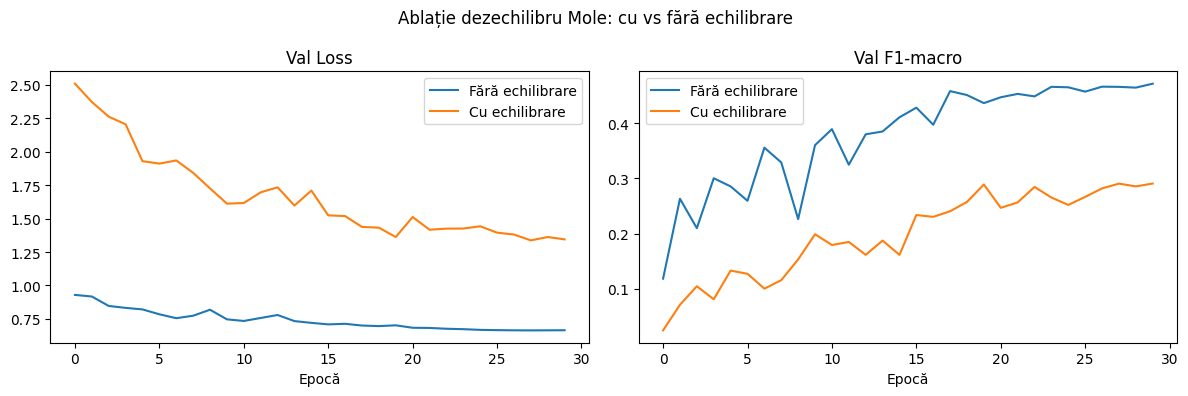


Ablație dezechilibru — Face:
  fără echilibrare...
Ep 005 | tr_loss=1.5505 tr_acc=0.420 | val_loss=1.5372 val_acc=0.433 F1=0.165
Ep 010 | tr_loss=1.3031 tr_acc=0.523 | val_loss=1.2741 val_acc=0.532 F1=0.336
Ep 015 | tr_loss=1.1177 tr_acc=0.600 | val_loss=1.3545 val_acc=0.505 F1=0.362
Ep 020 | tr_loss=1.0021 tr_acc=0.641 | val_loss=1.0044 val_acc=0.643 F1=0.452
Ep 025 | tr_loss=0.9368 tr_acc=0.666 | val_loss=0.9981 val_acc=0.626 F1=0.496
Ep 030 | tr_loss=0.9110 tr_acc=0.679 | val_loss=0.9957 val_acc=0.642 F1=0.504
Best val F1-macro: 0.5097 — model salvat în cnn_Face_noeq_best.pt
  cu echilibrare (sampler + weighted CE)...
Ep 005 | tr_loss=1.4561 tr_acc=0.201 | val_loss=2.6850 val_acc=0.062 F1=0.049
Ep 010 | tr_loss=1.2781 tr_acc=0.280 | val_loss=2.3792 val_acc=0.096 F1=0.120
Ep 015 | tr_loss=1.1418 tr_acc=0.325 | val_loss=2.5481 val_acc=0.121 F1=0.128
Ep 020 | tr_loss=1.0026 tr_acc=0.389 | val_loss=2.2905 val_acc=0.163 F1=0.180
Ep 025 | tr_loss=0.9168 tr_acc=0.423 | val_loss=2.2912 val

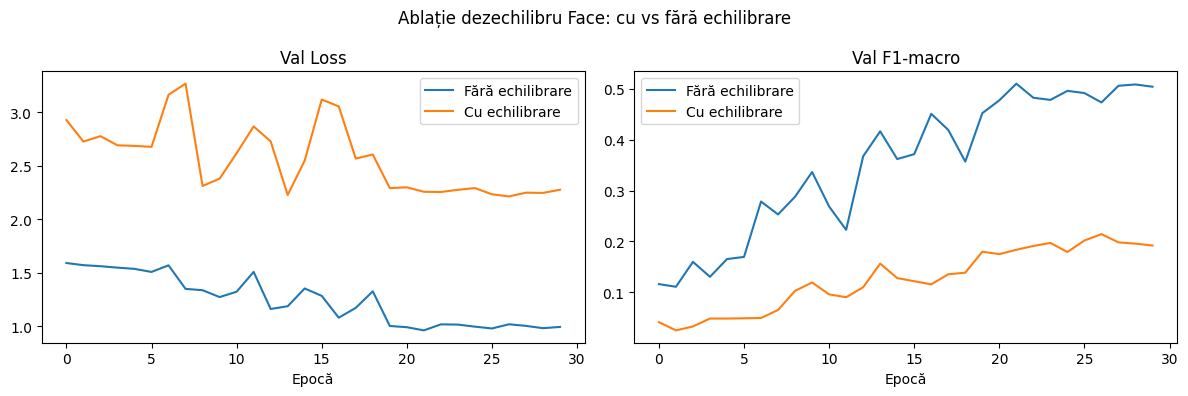

In [25]:
# Fără tehnici de echilibrare: loader normal + CE simplu
for ds_name, train_ds, val_loader_ds, num_cls, fk in [
    ('Mole', mole_train_ds, mole_val_loader, NUM_CLASSES_MOLE, 5),
    ('Face', face_train_ds, face_val_loader, NUM_CLASSES_FACE, 3),
]:
    print(f'\nAblație dezechilibru — {ds_name}:')

    # Fără echilibrare
    loader_unbal = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)
    crit_plain   = nn.CrossEntropyLoss()
    m_noeq = CNN(num_cls, first_kernel=fk, use_batchnorm=True).to(device)
    opt_   = optim.Adam(m_noeq.parameters(), lr=1e-3, weight_decay=1e-4)
    sched_ = CosineAnnealingLR(opt_, T_max=NUM_EPOCHS_CNN)
    print('  fără echilibrare...')
    hist_noeq = train_model(m_noeq, loader_unbal, val_loader_ds,
                             crit_plain, opt_, sched_,
                             NUM_EPOCHS_CNN, f'cnn_{ds_name}_noeq', device)

    # Cu sampler + weighted CE
    sampler_  = get_weighted_sampler(train_ds, num_cls)
    loader_eq = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler_, num_workers=0, drop_last=True)
    weights_  = get_class_weights(train_ds, num_cls, device)
    crit_eq   = nn.CrossEntropyLoss(weight=weights_)
    m_eq = CNN(num_cls, first_kernel=fk, use_batchnorm=True).to(device)
    opt2 = optim.Adam(m_eq.parameters(), lr=1e-3, weight_decay=1e-4)
    sched2 = CosineAnnealingLR(opt2, T_max=NUM_EPOCHS_CNN)
    print('  cu echilibrare (sampler + weighted CE)...')
    hist_eq = train_model(m_eq, loader_eq, val_loader_ds,
                           crit_eq, opt2, sched2,
                           NUM_EPOCHS_CNN, f'cnn_{ds_name}_eq', device)

    # Grafic
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f'Ablație dezechilibru {ds_name}: cu vs fără echilibrare')
    for ax, key, ylabel in zip(axes, ['val_loss', 'val_f1_macro'], ['Val Loss', 'Val F1-macro']):
        ax.plot(hist_noeq[key], label='Fără echilibrare')
        ax.plot(hist_eq[key],   label='Cu echilibrare')
        ax.set_title(ylabel); ax.set_xlabel('Epocă'); ax.legend()
    plt.tight_layout()
    plt.savefig(f'ablatie_echilibru_{ds_name}.png', dpi=100)
    plt.show()

    if ds_name == 'Mole':
        hist_noeq_mole = hist_noeq
        hist_eq_mole   = hist_eq
    else:
        hist_noeq_face = hist_noeq
        hist_eq_face   = hist_eq

---
## 3.4 Fine-tuning (ResNet-18) + 3.5 Ablație: cu vs fără LR Warmup

In [26]:
# Transformări pentru fine-tuning (224×224, statistici ImageNet)
ft_train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
ft_val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# DataLoader-e fine-tuning
mole_ft_train = MoleDataset(os.path.join(MOLE_DIR, 'train.csv'), os.path.join(MOLE_DIR, 'train'), ft_train_transform)
mole_ft_val   = MoleDataset(os.path.join(MOLE_DIR, 'test.csv'),  os.path.join(MOLE_DIR, 'test'),  ft_val_transform)
mole_ft_sampler = get_weighted_sampler(mole_ft_train, NUM_CLASSES_MOLE)
mole_ft_loader  = DataLoader(mole_ft_train, batch_size=32, sampler=mole_ft_sampler, num_workers=0, drop_last=True)
mole_ft_val_loader = DataLoader(mole_ft_val, batch_size=32, shuffle=False, num_workers=0)

face_ft_train = FaceDataset(os.path.join(FACE_DIR, 'splits', 'train.csv'),      FACE_DIR, ft_train_transform)
face_ft_val   = FaceDataset(os.path.join(FACE_DIR, 'splits', 'local_test.csv'), FACE_DIR, ft_val_transform)
face_ft_sampler = get_weighted_sampler(face_ft_train, NUM_CLASSES_FACE)
face_ft_loader  = DataLoader(face_ft_train, batch_size=32, sampler=face_ft_sampler, num_workers=0, drop_last=True)
face_ft_val_loader = DataLoader(face_ft_val, batch_size=32, shuffle=False, num_workers=0)

print('DataLoader-e fine-tuning gata.')

DataLoader-e fine-tuning gata.


In [27]:
def build_resnet18(num_classes):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


NUM_EPOCHS_FT = 35
WARMUP_EPOCHS = 5

def make_scheduler_with_warmup(optimizer, warmup_ep, total_ep):
    warmup = LambdaLR(optimizer, lr_lambda=lambda e: (e + 1) / warmup_ep)
    cosine = CosineAnnealingLR(optimizer, T_max=total_ep - warmup_ep)
    return SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[warmup_ep])

def make_scheduler_no_warmup(optimizer, total_ep):
    return CosineAnnealingLR(optimizer, T_max=total_ep)

print('Functii fine-tuning definite.')


Funcții fine-tuning definite.



Fine-tuning ResNet-18 Mole — cu warmup...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/anaciurea/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


Ep 005 | tr_loss=0.6309 tr_acc=0.514 | val_loss=1.6368 val_acc=0.168 F1=0.228
Ep 010 | tr_loss=0.5422 tr_acc=0.573 | val_loss=1.4678 val_acc=0.295 F1=0.292
Ep 015 | tr_loss=0.5202 tr_acc=0.583 | val_loss=1.4672 val_acc=0.307 F1=0.294
Ep 020 | tr_loss=0.4984 tr_acc=0.593 | val_loss=1.4961 val_acc=0.296 F1=0.280
Best val F1-macro: 0.3008 — model salvat în mole_ft_warmup_best.pt

Fine-tuning ResNet-18 Mole — fără warmup...
Ep 005 | tr_loss=0.6043 tr_acc=0.541 | val_loss=1.6678 val_acc=0.238 F1=0.251
Ep 010 | tr_loss=0.5325 tr_acc=0.573 | val_loss=1.4655 val_acc=0.340 F1=0.308
Ep 015 | tr_loss=0.5297 tr_acc=0.591 | val_loss=1.5054 val_acc=0.313 F1=0.287
Ep 020 | tr_loss=0.5141 tr_acc=0.587 | val_loss=1.4828 val_acc=0.315 F1=0.297
Best val F1-macro: 0.3142 — model salvat în mole_ft_nowarmup_best.pt


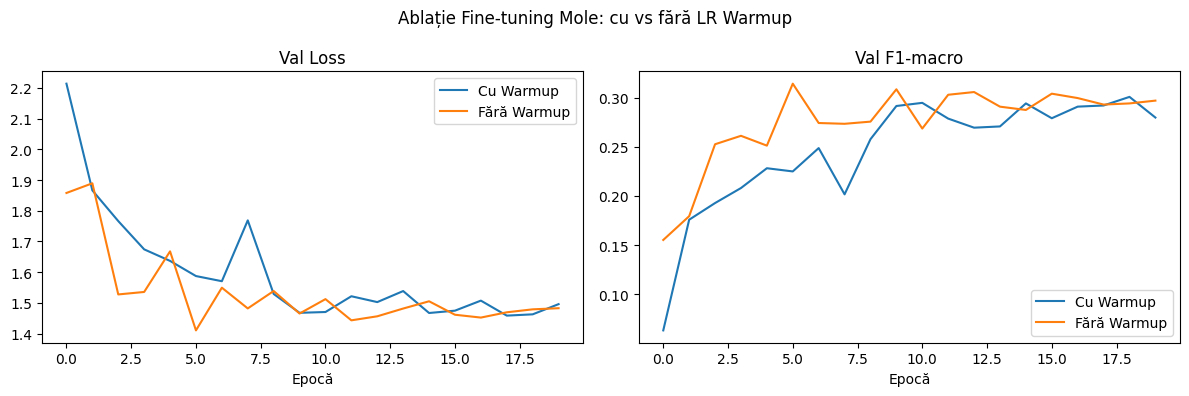

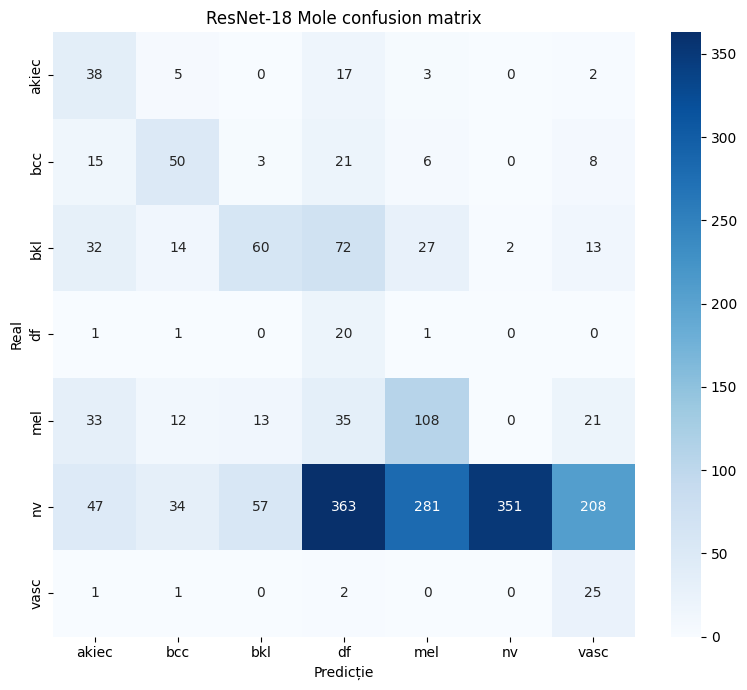

              precision    recall  f1-score   support

       akiec       0.23      0.58      0.33        65
         bcc       0.43      0.49      0.45       103
         bkl       0.45      0.27      0.34       220
          df       0.04      0.87      0.07        23
         mel       0.25      0.49      0.33       222
          nv       0.99      0.26      0.41      1341
        vasc       0.09      0.86      0.16        29

    accuracy                           0.33      2003
   macro avg       0.35      0.55      0.30      2003
weighted avg       0.77      0.33      0.39      2003



In [28]:
# Fine-tuning ResNet-18 pe MOLE — cu și fără warmup
for warmup, label, run_id in [(True, 'cu warmup', 'mole_ft_warmup'), (False, 'fără warmup', 'mole_ft_nowarmup')]:
    print(f'\nFine-tuning ResNet-18 Mole — {label}...')
    m = build_resnet18(NUM_CLASSES_MOLE).to(device)
    backbone_params = [p for n, p in m.named_parameters() if 'fc' not in n]
    head_params     = list(m.fc.parameters())
    opt = optim.Adam([
        {'params': backbone_params, 'lr': 2e-4},
        {'params': head_params,     'lr': 1e-3}
    ], weight_decay=1e-4)
    sched = make_scheduler_with_warmup(opt, WARMUP_EPOCHS, NUM_EPOCHS_FT) if warmup \
            else make_scheduler_no_warmup(opt, NUM_EPOCHS_FT)
    hist = train_model(m, mole_ft_loader, mole_ft_val_loader,
                       criterion_mole, opt, sched,
                       NUM_EPOCHS_FT, run_id, device)
    globals()[f'hist_ft_{run_id}'] = hist

# Grafic ablație warmup — Mole
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Ablație Fine-tuning Mole: cu vs fără LR Warmup')
for ax, key, ylabel in zip(axes, ['val_loss', 'val_f1_macro'], ['Val Loss', 'Val F1-macro']):
    ax.plot(hist_ft_mole_ft_warmup[key],   label='Cu Warmup')
    ax.plot(hist_ft_mole_ft_nowarmup[key], label='Fără Warmup')
    ax.set_title(ylabel); ax.set_xlabel('Epocă'); ax.legend()
plt.tight_layout()
plt.savefig('ablatie_ft_warmup_mole.png', dpi=100)
plt.show()

# Matricea de confuzie — cel mai bun ResNet-18 Mole (cu warmup)
resnet_mole_best = build_resnet18(NUM_CLASSES_MOLE).to(device)
resnet_mole_best.load_state_dict(torch.load('mole_ft_warmup_best.pt', map_location=device))
plot_confusion_matrix(resnet_mole_best, mole_ft_val_loader, MOLE_IDX2CLASS, device,
                      'ResNet-18 Mole confusion matrix')



Fine-tuning ResNet-18 Face — cu warmup...
Ep 005 | tr_loss=1.1532 tr_acc=0.368 | val_loss=2.3688 val_acc=0.165 F1=0.184
Ep 010 | tr_loss=1.1107 tr_acc=0.403 | val_loss=2.3671 val_acc=0.223 F1=0.232
Ep 015 | tr_loss=1.0851 tr_acc=0.410 | val_loss=2.4254 val_acc=0.186 F1=0.199
Ep 020 | tr_loss=1.0475 tr_acc=0.422 | val_loss=2.4108 val_acc=0.189 F1=0.204
Best val F1-macro: 0.2315 — model salvat în face_ft_warmup_best.pt

Fine-tuning ResNet-18 Face — fără warmup...
Ep 005 | tr_loss=1.1493 tr_acc=0.377 | val_loss=2.2148 val_acc=0.192 F1=0.205
Ep 010 | tr_loss=1.0875 tr_acc=0.405 | val_loss=2.5202 val_acc=0.179 F1=0.197
Ep 015 | tr_loss=1.0784 tr_acc=0.414 | val_loss=2.4332 val_acc=0.183 F1=0.198
Ep 020 | tr_loss=1.0614 tr_acc=0.420 | val_loss=2.3398 val_acc=0.194 F1=0.209
Best val F1-macro: 0.2352 — model salvat în face_ft_nowarmup_best.pt


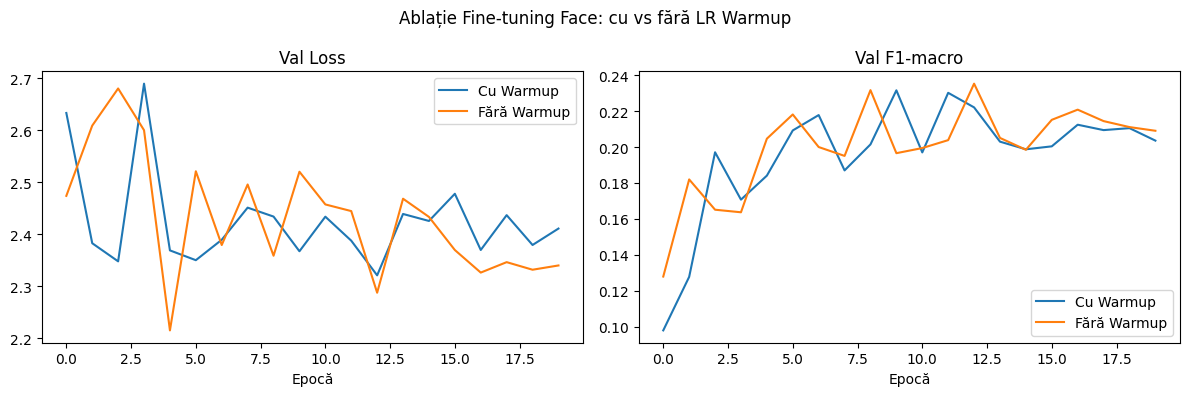

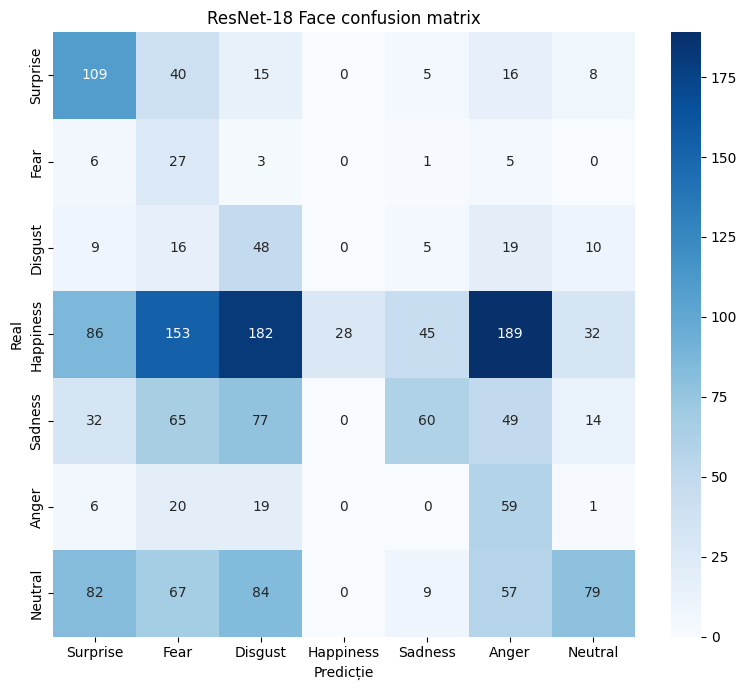

              precision    recall  f1-score   support

    Surprise       0.33      0.56      0.42       193
        Fear       0.07      0.64      0.13        42
     Disgust       0.11      0.45      0.18       107
   Happiness       1.00      0.04      0.08       715
     Sadness       0.48      0.20      0.28       297
       Anger       0.15      0.56      0.24       105
     Neutral       0.55      0.21      0.30       378

    accuracy                           0.22      1837
   macro avg       0.38      0.38      0.23      1837
weighted avg       0.63      0.22      0.21      1837



In [29]:
# Fine-tuning ResNet-18 pe FACE — cu și fără warmup
for warmup, label, run_id in [(True, 'cu warmup', 'face_ft_warmup'), (False, 'fără warmup', 'face_ft_nowarmup')]:
    print(f'\nFine-tuning ResNet-18 Face — {label}...')
    m = build_resnet18(NUM_CLASSES_FACE).to(device)
    backbone_params = [p for n, p in m.named_parameters() if 'fc' not in n]
    head_params     = list(m.fc.parameters())
    opt = optim.Adam([
        {'params': backbone_params, 'lr': 2e-4},
        {'params': head_params,     'lr': 1e-3}
    ], weight_decay=1e-4)
    sched = make_scheduler_with_warmup(opt, WARMUP_EPOCHS, NUM_EPOCHS_FT) if warmup \
            else make_scheduler_no_warmup(opt, NUM_EPOCHS_FT)
    hist = train_model(m, face_ft_loader, face_ft_val_loader,
                       criterion_face, opt, sched,
                       NUM_EPOCHS_FT, run_id, device)
    globals()[f'hist_ft_{run_id}'] = hist

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Ablație Fine-tuning Face: cu vs fără LR Warmup')
for ax, key, ylabel in zip(axes, ['val_loss', 'val_f1_macro'], ['Val Loss', 'Val F1-macro']):
    ax.plot(hist_ft_face_ft_warmup[key],   label='Cu Warmup')
    ax.plot(hist_ft_face_ft_nowarmup[key], label='Fără Warmup')
    ax.set_title(ylabel); ax.set_xlabel('Epocă'); ax.legend()
plt.tight_layout()
plt.savefig('ablatie_ft_warmup_face.png', dpi=100)
plt.show()

# Matricea de confuzie — cel mai bun ResNet-18 Face (cu warmup)
resnet_face_best = build_resnet18(NUM_CLASSES_FACE).to(device)
resnet_face_best.load_state_dict(torch.load('face_ft_warmup_best.pt', map_location=device))
plot_confusion_matrix(resnet_face_best, face_ft_val_loader, FACE_IDX2CLASS, device,
                      'ResNet-18 Face confusion matrix')


---
## Generare predicții pentru Kaggle (remote test)

---
## BONUS — Curriculum Learning (Secțiunea 7)

Antrenare CNN Mole cu Curriculum Learning...
Ep 005 frac=0.49 subset=2924 | val_loss=10.7359 F1=0.115
Ep 010 frac=0.72 subset=4326 | val_loss=5.4639 F1=0.144
Ep 015 frac=0.95 subset=5728 | val_loss=3.1308 F1=0.277
Ep 020 frac=1.00 subset=6009 | val_loss=1.4100 F1=0.316
Ep 025 frac=1.00 subset=6009 | val_loss=1.2884 F1=0.357
Ep 030 frac=1.00 subset=6009 | val_loss=1.3070 F1=0.373
Best val F1-macro: 0.3727


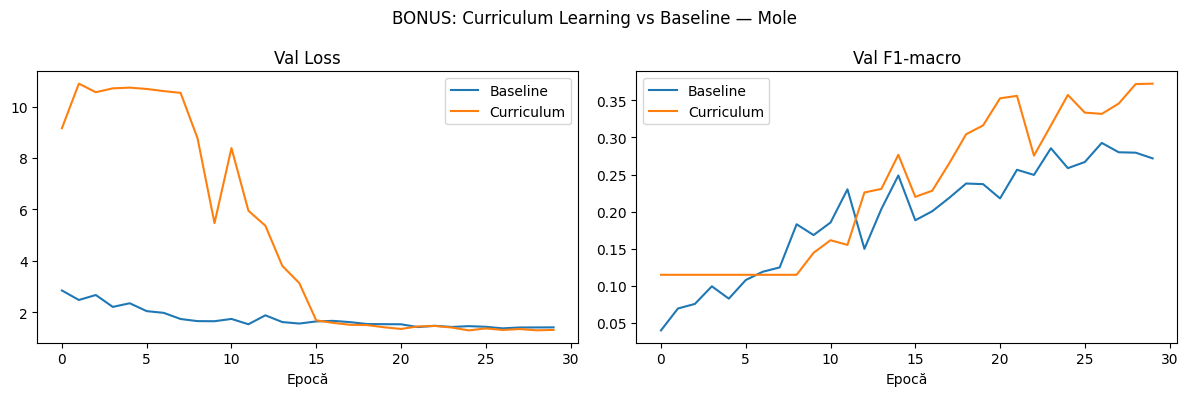

In [31]:
# Folosim self-paced learning pe setul Mole:
# Dificultatea unui exemplu = loss-ul curent al modelului pe acel exemplu.
# Pornim cu 30% din date (cele mai ușoare) și creștem pragul cu 5% pe epocă.

criterion_no_red = nn.CrossEntropyLoss(weight=mole_weights, reduction='none')

@torch.no_grad()
def per_sample_losses(model, dataset, criterion_nr, device, batch_size=128):
    model.eval()
    losses = []
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        l = criterion_nr(model(images), labels)
        losses.append(l.cpu())
    return torch.cat(losses)


def train_curriculum(model, train_ds, val_loader, criterion, criterion_nr,
                     optimizer, num_epochs, run_name, device, start_frac=0.3):
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, run_name))
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
               'val_f1_macro': []}
    best_f1 = 0.0

    for epoch in range(num_epochs):
        # Calculăm loss per exemplu și selectăm subsetul curent
        losses = per_sample_losses(model, train_ds, criterion_nr, device)
        frac = min(1.0, start_frac + (1 - start_frac) * (epoch / (num_epochs * 0.5)))
        threshold = torch.quantile(losses, frac)
        easy_idx  = (losses <= threshold).nonzero(as_tuple=True)[0].tolist()

        subset = Subset(train_ds, easy_idx)
        loader = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)

        tr_loss, tr_acc = train_one_epoch(model, loader, criterion, optimizer, device)
        va_loss, va_acc, va_f1m, _, _ = evaluate(model, val_loader, criterion, device)

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        history['val_f1_macro'].append(va_f1m)

        writer.add_scalar('Loss/train', tr_loss, epoch)
        writer.add_scalar('Loss/val',   va_loss, epoch)
        writer.add_scalar('F1_macro/val', va_f1m, epoch)
        writer.add_scalar('CurriculumFrac', frac, epoch)

        if va_f1m > best_f1:
            best_f1 = va_f1m
            torch.save(model.state_dict(), f'{run_name}_best.pt')

        if (epoch + 1) % 5 == 0:
            print(f'Ep {epoch+1:03d} frac={frac:.2f} subset={len(easy_idx)} | '
                  f'val_loss={va_loss:.4f} F1={va_f1m:.3f}')

    writer.close()
    print(f'Best val F1-macro: {best_f1:.4f}')
    return history


# Antrenare curriculum vs baseline
NUM_EPOCHS_CL = 30
mole_cl_ds = MoleDataset(os.path.join(MOLE_DIR, 'train.csv'), os.path.join(MOLE_DIR, 'train'), mole_train_transform)

model_cl = CNN(NUM_CLASSES_MOLE, first_kernel=5, use_batchnorm=True).to(device)
opt_cl   = optim.Adam(model_cl.parameters(), lr=1e-3, weight_decay=1e-4)

print('Antrenare CNN Mole cu Curriculum Learning...')
hist_cl = train_curriculum(
    model_cl, mole_cl_ds, mole_val_loader,
    criterion_mole, criterion_no_red,
    opt_cl, NUM_EPOCHS_CL,
    'cnn_mole_curriculum', device
)

# Comparație cu baseline (CNN antrenat standard la 30 epoci)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('BONUS: Curriculum Learning vs Baseline — Mole')
for ax, key, ylabel in zip(axes, ['val_loss', 'val_f1_macro'], ['Val Loss', 'Val F1-macro']):
    ax.plot(hist_cnn_mole[key], label='Baseline')
    ax.plot(hist_cl[key],       label='Curriculum')
    ax.set_title(ylabel); ax.set_xlabel('Epocă'); ax.legend()
plt.tight_layout()
plt.savefig('bonus_curriculum_mole.png', dpi=100)
plt.show()

---
## Tabel sumar rezultate

In [32]:
def best_f1(hist):
    return max(hist['val_f1_macro'])

results = {
    'Model': [
        'MLP cu dropout (Mole)', 'MLP fără dropout (Mole)',
        'MLP cu dropout (Face)', 'MLP fără dropout (Face)',
        'CNN cu BatchNorm (Mole)', 'CNN fără BatchNorm (Mole)',
        'CNN cu BatchNorm (Face)', 'CNN fără BatchNorm (Face)',
        'CNN cu echilibrare (Mole)', 'CNN fără echilibrare (Mole)',
        'CNN cu echilibrare (Face)', 'CNN fără echilibrare (Face)',
        'ResNet-18 cu warmup (Mole)', 'ResNet-18 fără warmup (Mole)',
        'ResNet-18 cu warmup (Face)', 'ResNet-18 fără warmup (Face)',
    ],
    'Best Val F1-macro': [
        best_f1(hist_mlp_mole),    best_f1(hist_mlp_mole_nd),
        best_f1(hist_mlp_face),    best_f1(hist_mlp_face_nd),
        best_f1(hist_cnn_mole),    best_f1(hist_cnn_mole_nobn),
        best_f1(hist_cnn_face),    best_f1(hist_cnn_face_nobn),
        best_f1(hist_eq_mole),     best_f1(hist_noeq_mole),
        best_f1(hist_eq_face),          best_f1(hist_noeq_face),
        best_f1(hist_ft_mole_ft_warmup),   best_f1(hist_ft_mole_ft_nowarmup),
        best_f1(hist_ft_face_ft_warmup),   best_f1(hist_ft_face_ft_nowarmup),
    ]
}

df_results = pd.DataFrame(results)
df_results['Best Val F1-macro'] = df_results['Best Val F1-macro'].round(4)
print(df_results.to_string(index=False))

                       Model  Best Val F1-macro
       MLP cu dropout (Mole)             0.2276
     MLP fără dropout (Mole)             0.3050
       MLP cu dropout (Face)             0.2252
     MLP fără dropout (Face)             0.3100
     CNN cu BatchNorm (Mole)             0.2927
   CNN fără BatchNorm (Mole)             0.2229
     CNN cu BatchNorm (Face)             0.1964
   CNN fără BatchNorm (Face)             0.0995
   CNN cu echilibrare (Mole)             0.2906
 CNN fără echilibrare (Mole)             0.4714
   CNN cu echilibrare (Face)             0.2145
 CNN fără echilibrare (Face)             0.5097
  ResNet-18 cu warmup (Mole)             0.3008
ResNet-18 fără warmup (Mole)             0.3142
  ResNet-18 cu warmup (Face)             0.2315
ResNet-18 fără warmup (Face)             0.2352


---
## 3.4b Fine-tuning MobileNet-v2 + Ablație LR Warmup


Fine-tuning MobileNet-v2 Mole — cu warmup...
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /Users/anaciurea/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100.0%


Ep 005 | tr_loss=0.6239 tr_acc=0.547 | val_loss=1.4772 val_acc=0.297 F1=0.293
Ep 010 | tr_loss=0.5601 tr_acc=0.577 | val_loss=1.5588 val_acc=0.326 F1=0.298
Ep 015 | tr_loss=0.5377 tr_acc=0.591 | val_loss=1.2905 val_acc=0.415 F1=0.334
Ep 020 | tr_loss=0.5271 tr_acc=0.591 | val_loss=1.3280 val_acc=0.401 F1=0.338
Best val F1-macro: 0.3740 — model salvat în mole_mv2_warmup_best.pt

Fine-tuning MobileNet-v2 Mole — fara warmup...
Ep 005 | tr_loss=0.5866 tr_acc=0.569 | val_loss=1.3395 val_acc=0.395 F1=0.325
Ep 010 | tr_loss=0.5387 tr_acc=0.592 | val_loss=1.3478 val_acc=0.415 F1=0.336
Ep 015 | tr_loss=0.5311 tr_acc=0.591 | val_loss=1.3817 val_acc=0.409 F1=0.329
Ep 020 | tr_loss=0.4941 tr_acc=0.606 | val_loss=1.3571 val_acc=0.403 F1=0.325
Best val F1-macro: 0.3375 — model salvat în mole_mv2_nowarmup_best.pt


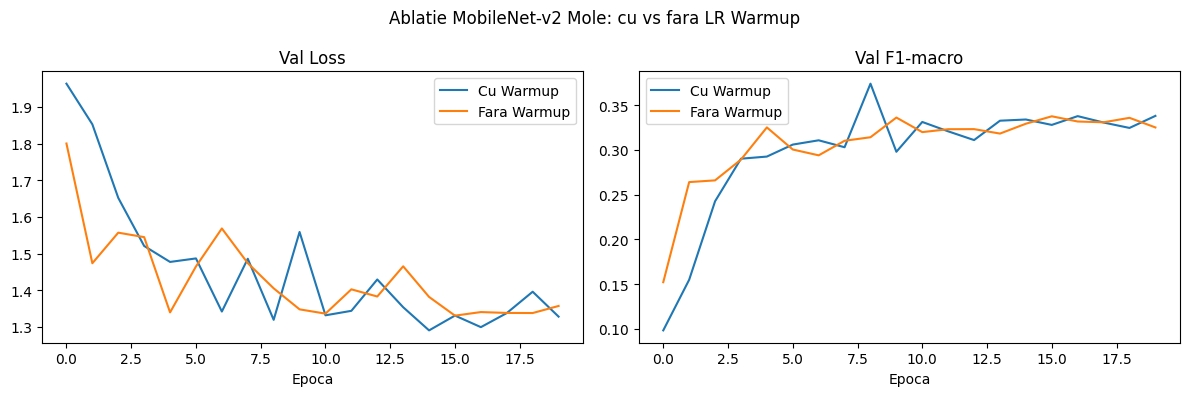

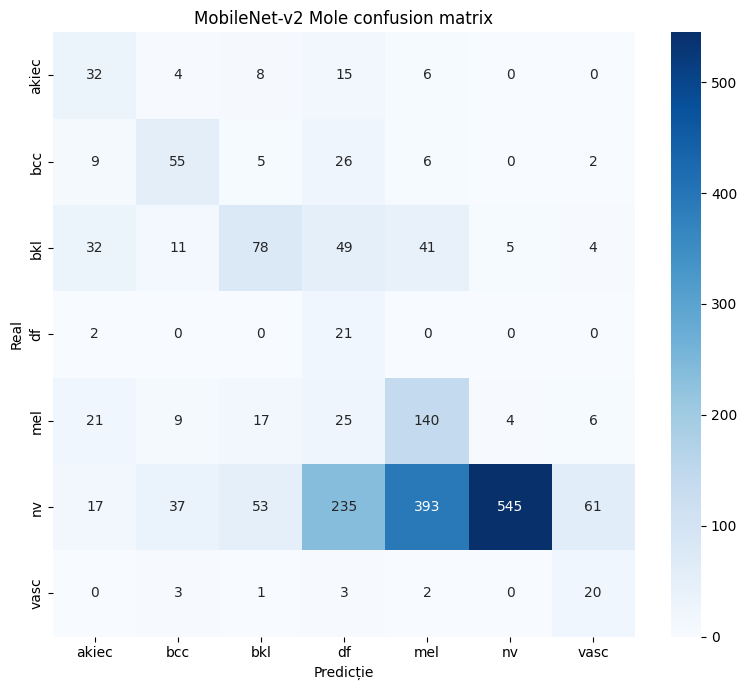

              precision    recall  f1-score   support

       akiec       0.28      0.49      0.36        65
         bcc       0.46      0.53      0.50       103
         bkl       0.48      0.35      0.41       220
          df       0.06      0.91      0.11        23
         mel       0.24      0.63      0.35       222
          nv       0.98      0.41      0.58      1341
        vasc       0.22      0.69      0.33        29

    accuracy                           0.44      2003
   macro avg       0.39      0.57      0.37      2003
weighted avg       0.77      0.44      0.51      2003



In [33]:
def build_mobilenetv2(num_classes):
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model


# Fine-tuning MobileNet-v2 pe MOLE — cu si fara warmup
hist_mv2_mole = {}
for warmup, label, run_id in [(True, 'cu warmup', 'mole_mv2_warmup'), (False, 'fara warmup', 'mole_mv2_nowarmup')]:
    print(f'\nFine-tuning MobileNet-v2 Mole — {label}...')
    m = build_mobilenetv2(NUM_CLASSES_MOLE).to(device)
    backbone_params = [p for n, p in m.named_parameters() if 'classifier.1' not in n]
    head_params     = list(m.classifier[1].parameters())
    opt = optim.Adam([
        {'params': backbone_params, 'lr': 2e-4},
        {'params': head_params,     'lr': 1e-3}
    ], weight_decay=1e-4)
    sched = make_scheduler_with_warmup(opt, WARMUP_EPOCHS, NUM_EPOCHS_FT) if warmup \
            else make_scheduler_no_warmup(opt, NUM_EPOCHS_FT)
    hist = train_model(m, mole_ft_loader, mole_ft_val_loader,
                       criterion_mole, opt, sched,
                       NUM_EPOCHS_FT, run_id, device)
    hist_mv2_mole[label] = hist
    globals()[f'hist_mv2_{run_id}'] = hist

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Ablatie MobileNet-v2 Mole: cu vs fara LR Warmup')
for ax, key, ylabel in zip(axes, ['val_loss', 'val_f1_macro'], ['Val Loss', 'Val F1-macro']):
    ax.plot(hist_mv2_mole['cu warmup'][key],   label='Cu Warmup')
    ax.plot(hist_mv2_mole['fara warmup'][key], label='Fara Warmup')
    ax.set_title(ylabel); ax.set_xlabel('Epoca'); ax.legend()
plt.tight_layout()
plt.savefig('ablatie_mv2_warmup_mole.png', dpi=100)
plt.show()

# Matricea de confuzie — cel mai bun MobileNet-v2 Mole (cu warmup)
mv2_mole_best = build_mobilenetv2(NUM_CLASSES_MOLE).to(device)
mv2_mole_best.load_state_dict(torch.load('mole_mv2_warmup_best.pt', map_location=device))
plot_confusion_matrix(mv2_mole_best, mole_ft_val_loader, MOLE_IDX2CLASS, device,
                      'MobileNet-v2 Mole confusion matrix')



Fine-tuning MobileNet-v2 Face — cu warmup...
Ep 005 | tr_loss=1.2339 tr_acc=0.352 | val_loss=2.2715 val_acc=0.188 F1=0.181
Ep 010 | tr_loss=1.1529 tr_acc=0.384 | val_loss=2.5979 val_acc=0.171 F1=0.186
Ep 015 | tr_loss=1.1176 tr_acc=0.399 | val_loss=2.4649 val_acc=0.169 F1=0.175
Ep 020 | tr_loss=1.1323 tr_acc=0.391 | val_loss=2.3583 val_acc=0.186 F1=0.195
Best val F1-macro: 0.2102 — model salvat în face_mv2_warmup_best.pt

Fine-tuning MobileNet-v2 Face — fara warmup...
Ep 005 | tr_loss=1.2263 tr_acc=0.364 | val_loss=2.9089 val_acc=0.135 F1=0.142
Ep 010 | tr_loss=1.1914 tr_acc=0.371 | val_loss=2.4883 val_acc=0.167 F1=0.163
Ep 015 | tr_loss=1.1311 tr_acc=0.396 | val_loss=2.4239 val_acc=0.176 F1=0.185
Ep 020 | tr_loss=1.1382 tr_acc=0.393 | val_loss=2.3919 val_acc=0.185 F1=0.194
Best val F1-macro: 0.2146 — model salvat în face_mv2_nowarmup_best.pt


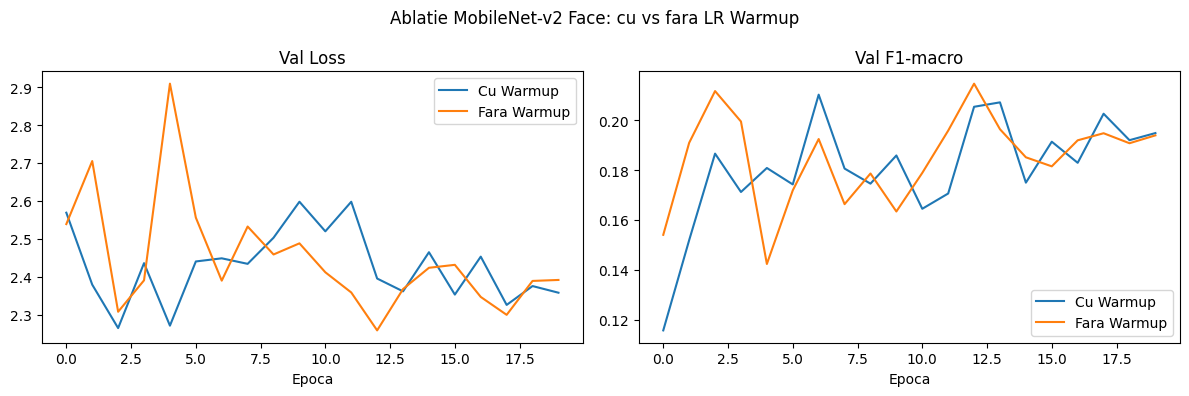

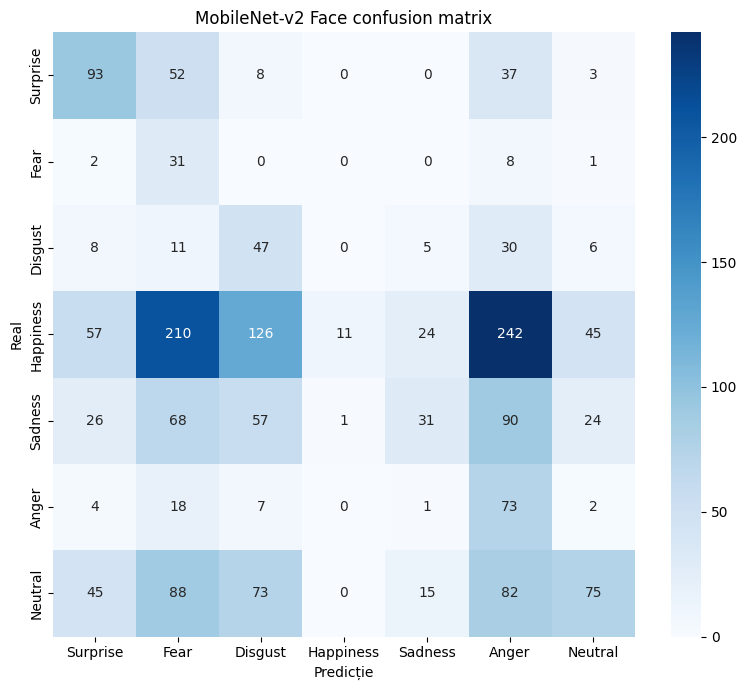

              precision    recall  f1-score   support

    Surprise       0.40      0.48      0.43       193
        Fear       0.06      0.74      0.12        42
     Disgust       0.15      0.44      0.22       107
   Happiness       0.92      0.02      0.03       715
     Sadness       0.41      0.10      0.17       297
       Anger       0.13      0.70      0.22       105
     Neutral       0.48      0.20      0.28       378

    accuracy                           0.20      1837
   macro avg       0.36      0.38      0.21      1837
weighted avg       0.58      0.20      0.17      1837



In [34]:
# Fine-tuning MobileNet-v2 pe FACE — cu si fara warmup
hist_mv2_face = {}
for warmup, label, run_id in [(True, 'cu warmup', 'face_mv2_warmup'), (False, 'fara warmup', 'face_mv2_nowarmup')]:
    print(f'\nFine-tuning MobileNet-v2 Face — {label}...')
    m = build_mobilenetv2(NUM_CLASSES_FACE).to(device)
    backbone_params = [p for n, p in m.named_parameters() if 'classifier.1' not in n]
    head_params     = list(m.classifier[1].parameters())
    opt = optim.Adam([
        {'params': backbone_params, 'lr': 2e-4},
        {'params': head_params,     'lr': 1e-3}
    ], weight_decay=1e-4)
    sched = make_scheduler_with_warmup(opt, WARMUP_EPOCHS, NUM_EPOCHS_FT) if warmup \
            else make_scheduler_no_warmup(opt, NUM_EPOCHS_FT)
    hist = train_model(m, face_ft_loader, face_ft_val_loader,
                       criterion_face, opt, sched,
                       NUM_EPOCHS_FT, run_id, device)
    hist_mv2_face[label] = hist
    globals()[f'hist_mv2_{run_id}'] = hist

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Ablatie MobileNet-v2 Face: cu vs fara LR Warmup')
for ax, key, ylabel in zip(axes, ['val_loss', 'val_f1_macro'], ['Val Loss', 'Val F1-macro']):
    ax.plot(hist_mv2_face['cu warmup'][key],   label='Cu Warmup')
    ax.plot(hist_mv2_face['fara warmup'][key], label='Fara Warmup')
    ax.set_title(ylabel); ax.set_xlabel('Epoca'); ax.legend()
plt.tight_layout()
plt.savefig('ablatie_mv2_warmup_face.png', dpi=100)
plt.show()

# Matricea de confuzie — cel mai bun MobileNet-v2 Face (cu warmup)
mv2_face_best = build_mobilenetv2(NUM_CLASSES_FACE).to(device)
mv2_face_best.load_state_dict(torch.load('face_mv2_warmup_best.pt', map_location=device))
plot_confusion_matrix(mv2_face_best, face_ft_val_loader, FACE_IDX2CLASS, device,
                      'MobileNet-v2 Face confusion matrix')


---
## Generare submisii Kaggle (toate modelele)

In [35]:
import glob

# Mole: imagini in kaggle_test/
def predict_mole(model, transform, device):
    df = pd.read_csv(os.path.join(MOLE_DIR, 'kaggle_test.csv'))
    model.eval()
    preds = []
    with torch.no_grad():
        for _, row in df.iterrows():
            img = Image.open(os.path.join(MOLE_DIR, 'kaggle_test', row['imagine'])).convert('RGB')
            t = transform(img).unsqueeze(0).to(device)
            idx = model(t).argmax(1).item()
            preds.append(MOLE_IDX2CLASS[idx])
    df['diagnostic'] = preds
    return df[['imagine', 'diagnostic']]

# Face: scaneaza DATASET/test/** pentru a mapa filename -> path complet
_face_test_map = {}
for p in glob.glob(os.path.join(FACE_DIR, 'DATASET', 'test', '**', '*.jpg'), recursive=True):
    _face_test_map[os.path.basename(p)] = p

def predict_face(model, transform, device):
    df = pd.read_csv(os.path.join(FACE_DIR, 'splits', 'remote_test.csv'))
    model.eval()
    preds = []
    with torch.no_grad():
        for _, row in df.iterrows():
            img = Image.open(_face_test_map[row['id']]).convert('RGB')
            t = transform(img).unsqueeze(0).to(device)
            idx = model(t).argmax(1).item()
            preds.append(idx + 1)  # 0-indexed -> 1-indexed
    df['label'] = preds
    return df[['id', 'label']]

print('Functii de predictie Kaggle definite.')


Functii de predictie Kaggle definite.


In [36]:
os.makedirs('submissions', exist_ok=True)

# ====== MOLE submissions ======
mlp_mole.load_state_dict(torch.load('mlp_mole_dropout_best.pt', map_location=device))
predict_mole(mlp_mole, mole_val_transform, device).to_csv('submissions/mole_mlp.csv', index=False)
print('Salvat: submissions/mole_mlp.csv')

cnn_mole.load_state_dict(torch.load('cnn_mole_bn_best.pt', map_location=device))
predict_mole(cnn_mole, mole_val_transform, device).to_csv('submissions/mole_cnn.csv', index=False)
print('Salvat: submissions/mole_cnn.csv')

best_resnet_mole = build_resnet18(NUM_CLASSES_MOLE).to(device)
best_resnet_mole.load_state_dict(torch.load('mole_ft_warmup_best.pt', map_location=device))
predict_mole(best_resnet_mole, ft_val_transform, device).to_csv('submissions/mole_resnet18.csv', index=False)
print('Salvat: submissions/mole_resnet18.csv')

best_mv2_mole = build_mobilenetv2(NUM_CLASSES_MOLE).to(device)
best_mv2_mole.load_state_dict(torch.load('mole_mv2_warmup_best.pt', map_location=device))
predict_mole(best_mv2_mole, ft_val_transform, device).to_csv('submissions/mole_mobilenetv2.csv', index=False)
print('Salvat: submissions/mole_mobilenetv2.csv')

# ====== FACE submissions ======
mlp_face.load_state_dict(torch.load('mlp_face_dropout_best.pt', map_location=device))
predict_face(mlp_face, face_val_transform, device).to_csv('submissions/face_mlp.csv', index=False)
print('Salvat: submissions/face_mlp.csv')

cnn_face.load_state_dict(torch.load('cnn_face_bn_best.pt', map_location=device))
predict_face(cnn_face, face_val_transform, device).to_csv('submissions/face_cnn.csv', index=False)
print('Salvat: submissions/face_cnn.csv')

best_resnet_face = build_resnet18(NUM_CLASSES_FACE).to(device)
best_resnet_face.load_state_dict(torch.load('face_ft_warmup_best.pt', map_location=device))
predict_face(best_resnet_face, ft_val_transform, device).to_csv('submissions/face_resnet18.csv', index=False)
print('Salvat: submissions/face_resnet18.csv')

best_mv2_face = build_mobilenetv2(NUM_CLASSES_FACE).to(device)
best_mv2_face.load_state_dict(torch.load('face_mv2_warmup_best.pt', map_location=device))
predict_face(best_mv2_face, ft_val_transform, device).to_csv('submissions/face_mobilenetv2.csv', index=False)
print('Salvat: submissions/face_mobilenetv2.csv')

print('\nToate submisiile generate in folderul submissions/')


Salvat: submissions/mole_mlp.csv
Salvat: submissions/mole_cnn.csv
Salvat: submissions/mole_resnet18.csv
Salvat: submissions/mole_mobilenetv2.csv
Salvat: submissions/face_mlp.csv
Salvat: submissions/face_cnn.csv
Salvat: submissions/face_resnet18.csv
Salvat: submissions/face_mobilenetv2.csv

Toate submisiile generate in folderul submissions/
